# SARIMAX — Predicción de consumo diario del Metro de Medellín
## Versión con **horizonte H configurable** y **orígenes A / B / C**

Este notebook es **el mismo pipeline** del notebook de evaluación SARIMAX original (default vs tuneado,
walk-forward, meses atípicos, Optuna warm-started, importancia de exógenas, intervalos de MAPE, bandas
conformal y exportaciones). **El único cambio estructural** es la *unidad de predicción*:

| Antes | Ahora |
|-------|-------|
| "mes calendario de longitud variable" (`cutoff = día 1`, `end = MonthEnd`, 28–31 días) | **ventana de `H` días** a partir de un **origen** `t`, con orígenes configurables |

### Qué es cada cosa

* **`H`** — horizonte de predicción **fijo**, en días. Para cada origen `t` se entrena con todo lo anterior a `t`
  (ventana expandible, `index < t`) y se predice `[t, t+H-1]`. Si al final de los datos no caben `H` días, la ventana
  se recorta (solo en test) y se exige una longitud mínima `MIN_WINDOW` (≈ `max(20, H//2)`).
* **Régimen de orígenes** (un único generador: `generate_origins`):

| Código | Nombre | Configuración | Orígenes |
|--------|--------|---------------|----------|
| **A** | Rolling diario | `ORIGIN_MODE="step"`, `STEP=1` | un origen cada día |
| **B** | Rolling cada *s* días | `ORIGIN_MODE="step"`, `STEP=s` (7, 15, 30…) | un origen cada `s` días |
| **C** | Orígenes mensuales | `ORIGIN_MODE="month_start"` | día 1 de cada mes (como el notebook original, pero prediciendo `H` días desde ahí) |

### Cómo se construyen las vistas mensuales (pred vs real, MAPE por mes, heatmap, bandas…)
Las vistas siguen siendo **por mes calendario de test**. Como un mismo día `d` puede ser predicho por varios orígenes
(ventanas que se solapan), la serie predicha de un mes se arma con la **política fija `min lead por día`**:
para cada día se usa la predicción del **origen más reciente con origen ≤ d** (la de menor *lead time* `d − origen + 1`).
Los días que ninguna ventana cubre quedan como `NaN` (no se grafican ni entran en métricas). Cada panel lo dice en su subtítulo:
`Mes YYYY-MM | H=… | mode=… | step=… | agregación: min lead por día`.

### Degradación del error
**Siempre está definida por el horizonte de la corrida**: eje X = *lead time* `1, 2, …, H` (no "día del mes"), promediando
el error sobre las ventanas **estables** (no atípicas). Aplica igual a la sección de APE por horizonte.

### Meses / ventanas atípicas
* Vistas **mensuales**: un mes es atípico si está en `ATYPICAL_MONTHS` (igual que antes).
* Análisis **por ventana** (CV, degradación, importancia, calibración): una ventana de `H` días es atípica si la fracción
  de sus días que caen en `ATYPICAL_MONTHS` es `≥ ATYPICAL_OVERLAP_THR`. Las atípicas se excluyen de los promedios.

### Recomendación de costo
El modo **A** (`STEP=1`) ajusta un SARIMAX **por día** de test: es caro. Optuna usa como máximo `N_CV_FOLDS` orígenes de
validación en cualquier modo (submuestreados de forma uniforme), así que la búsqueda cuesta lo mismo en A, B o C; lo caro
de A es la **evaluación final**. Sugerencia: buscar en **C o B** y usar **A** solo en evaluación final con parámetros
fijados (`RUN_TUNING=False` + `TUNED_PARAMS_OVERRIDE`).

## 0. Setup (Colab)

Optuna y pmdarima no vienen preinstalados en Colab. Descomenta la celda para instalarlos (idempotente: si ya están, no hace nada).

In [ ]:
# Commented out IPython magic to ensure Python compatibility.
# Colab: instalar Optuna y pmdarima para la búsqueda guiada (idempotente)
%pip install -q optuna pmdarima

## 1. Imports

In [ ]:
import re, warnings, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from pandas.tseries.offsets import MonthBegin, MonthEnd
from scipy import stats
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/EAFIT/SIMAT/Metro/data/

# ── Suprimir warnings de convergencia limpiamente ─────────────────────────────
warnings.filterwarnings('ignore')
try:
    from statsmodels.tools.sm_exceptions import ConvergenceWarning
    warnings.filterwarnings('ignore', category=ConvergenceWarning)
except ImportError:
    pass

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11, 'figure.facecolor': 'white'})

# pmdarima para ajustar SARIMAX con variables exógenas
try:
    from pmdarima import ARIMA as PmARIMA
    HAS_PMDARIMA = True
    print("✓ pmdarima disponible")
except ImportError:
    HAS_PMDARIMA = False
    print("✗ pmdarima no instalado — ejecutar: pip install pmdarima")

# Optuna para la búsqueda guiada (warm-started). Si no está, se usa un fallback local.
try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    HAS_OPTUNA = True
    print(f"✓ Optuna {optuna.__version__}")
except ImportError:
    HAS_OPTUNA = False
    print("✗ Optuna no instalado — se usará búsqueda local (fallback). Instalar: pip install optuna")

try:
    from tqdm.auto import tqdm; HAS_TQDM = True
except ImportError:
    HAS_TQDM = False
    class tqdm:
        def __init__(self, iterable=None, **kw): self._it = iterable or []
        def __iter__(self): return iter(self._it)
        def set_postfix(self, **kw): pass

print("✓ Librerías base listas (SARIMAX)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/EAFIT/SIMAT/Metro/data
✓ pmdarima disponible
✓ Optuna 5.0.0
✓ Librerías base listas (SARIMAX)


## 2. Configuración global

**Ajusta aquí el horizonte `H`, el régimen de orígenes, las fechas, los meses atípicos, los parámetros de la búsqueda y el
punto de partida del tuning.** Para comparar A / B / C basta con cambiar `H`, `ORIGIN_MODE` y `STEP`.

| Parámetro | Descripción |
|-----------|-------------|
| **`H`** | Horizonte de predicción **fijo** (días). Cada origen predice `[t, t+H-1]`. |
| **`ORIGIN_MODE`** | `"month_start"` → **C** (día 1 de cada mes) · `"step"` → **A/B** (un origen cada `STEP` días). |
| **`STEP`** | Solo si `ORIGIN_MODE=="step"`: `1` = A (diario), `7/15/30…` = B. Se ignora en `month_start`. |
| `MIN_WINDOW` | Longitud mínima de una ventana **de test** (recortada al final de los datos). `None` → `max(20, H//2)`. |
| `ATYPICAL_OVERLAP_THR` | Una ventana es atípica si la fracción de sus días en `ATYPICAL_MONTHS` es ≥ este umbral. |
| `TRAIN_START` / `TEST_START` | Fechas de los splits. Test = desde `TEST_START` hasta el fin de los datos. |
| `N_CV_FOLDS` | **Máximo de orígenes** de walk-forward CV (zona pre-test, ventanas completas y estables). |
| `CV_SPAN_DAYS` | Cuántos días hacia atrás (antes del test) se consideran orígenes de CV (≈ un año de validación). |
| `N_TRIALS` | Iteraciones de la búsqueda guiada (warm-started desde `BEST_KNOWN_SARIMAX`). |
| `RUN_TUNING` | `False` → salta Optuna y usa `TUNED_PARAMS_OVERRIDE` (o `BEST_KNOWN_SARIMAX`). Útil para el modo A. |
| `PERM_MAX_ORIGINS` | Tope de orígenes estables usados en la importancia por permutación (acota costo en modos B/A). |
| `CI_LEVEL` | Nivel de confianza de los intervalos. |
| `RUN_EXPERIMENTS` / `EXPERIMENTOS` | Sección 20 (opcional): compara varias combinaciones `(H, modo, step)` con parámetros ya fijados. |

In [ ]:
# ─── AJUSTA AQUÍ ────────────────────────────────────────────────────────────
CSV_PATH    = 'features_sin_lags_limpio_new.csv'   # mismo archivo que el notebook original

TRAIN_START = '2018-01'   # Primer mes del train
TEST_START  = '2025-01'   # Primer mes del test  →  test = 2025-01 … fin de datos

# ══ HORIZONTE Y RÉGIMEN DE ORÍGENES (único cambio estructural) ═══════════════
H            = 7             # horizonte de predicción en días (fijo)
ORIGIN_MODE  = "step"  # "step" | "month_start"      (C = month_start ; A/B = step)
STEP         = 7             # solo si ORIGIN_MODE == "step": 1 = A, 7/15/30 = B
MIN_WINDOW   = None           # None → max(20, H//2)  (mínimo de días de una ventana de test recortada)
ATYPICAL_OVERLAP_THR = 0.5    # ventana atípica si fracción de días en ATYPICAL_MONTHS >= umbral
# ═════════════════════════════════════════════════════════════════════════════

N_CV_FOLDS   = 12         # MÁXIMO de orígenes de validación walk-forward (se submuestrean uniformemente si hay más)
CV_SPAN_DAYS = 365        # zona de validación: orígenes dentro de los últimos CV_SPAN_DAYS antes del test
MIN_TRAIN_DAYS = 365      # mínimo de historia para que un origen pueda ser origen de CV
N_TRIALS     = 15         # Iteraciones de la búsqueda guiada (warm-start incluido)
RUN_TUNING   = False       # False → sin Optuna; usa TUNED_PARAMS_OVERRIDE (o BEST_KNOWN_SARIMAX)
TUNED_PARAMS_OVERRIDE = None   # p.ej. dict(order=(3,0,0), seasonal_order=(1,0,2,7)) si RUN_TUNING=False
PERM_MAX_ORIGINS = 12     # orígenes estables máx. para importancia por permutación
MIN_MONTH_COVER_DAYS = 5  # un mes con menos días cubiertos por predicciones no se evalúa (NaN)
SEED         = 42
CI_LEVEL     = 0.90       # Nivel de confianza de los intervalos (MAPE mensual y bandas)
SEASONAL_M   = 7          # Periodicidad estacional: 7 = semanal

# Meses atípicos  ->  EXCLUIDOS de todos los promedios / análisis agregado (incluido el CV)
ATYPICAL_MONTHS = ['2025-03', '2025-05', '2025-10', '2025-11', '2025-12']
SHOW_ALL_MONTHS_IN_PLOTS = True

# ── Mejor SARIMAX hallado hasta ahora (MAPE CV ≈ 4.242 %) ───────────────────
#    La búsqueda guiada parte de esta ESTRUCTURA y refina su vecindario.
BEST_KNOWN_SARIMAX = dict(order=(3, 0, 0), seasonal_order=(1, 0, 2, SEASONAL_M))

# Baseline por defecto (para el contraste default vs tuned)
DEFAULT_SARIMAX = dict(order=(2, 1, 2), seasonal_order=(1, 0, 1, SEASONAL_M))

# ── Comparación A/B/C opcional (Sección 20). Usa los parámetros ya tuneados. ──
RUN_EXPERIMENTS = False
EXPERIMENTOS = [
    dict(name="C_mensual", ORIGIN_MODE="month_start", STEP=None, H=60),
    dict(name="B_step30",  ORIGIN_MODE="step",        STEP=30,   H=60),
    dict(name="A_diario",  ORIGIN_MODE="step",        STEP=1,    H=60),   # costoso: un fit por día de test
]
EXP_VARIANTS = ('tuned',)   # variantes evaluadas en la Sección 20 (añade 'default' si quieres)
# ─────────────────────────────────────────────────────────────────────────────

# ── Validación de la configuración ───────────────────────────────────────────
assert ORIGIN_MODE in ("step", "month_start"), "ORIGIN_MODE debe ser 'step' o 'month_start'"
assert isinstance(H, (int, np.integer)) and H >= 1, "H debe ser un entero >= 1"
if ORIGIN_MODE == "step":
    assert isinstance(STEP, (int, np.integer)) and STEP >= 1, "Con ORIGIN_MODE='step', STEP debe ser un entero >= 1"
STEP_TXT   = str(STEP) if ORIGIN_MODE == "step" else "—"          # para títulos
MIN_WINDOW_EFF = min(H, MIN_WINDOW if MIN_WINDOW is not None else max(20, H // 2))
AGG_POLICY = "min lead por día"     # política de agregación mensual (fija y documentada)
RUN_TAG    = f"H{H}_" + (f"step{STEP}" if ORIGIN_MODE == "step" else "month_start")   # sufijo de archivos exportados

rng = np.random.default_rng(SEED)

# Esquema de color: contraste DEFAULT vs TUNED (igual que el notebook original)
VARIANTS = ['default', 'tuned']
VCOLORS  = {'default': '#90A4AE', 'tuned': '#388E3C'}   # gris vs verde
SARIMAX_COLOR  = '#388E3C'
COLOR_ATYPICAL = '#6A1B9A'   # morado — meses/ventanas atípicos

def is_atyp(mes):
    """Mes calendario 'YYYY-MM' atípico (vistas mensuales)."""
    return mes in ATYPICAL_MONTHS

def run_subtitle(h=None, mode=None, step=None):
    """Texto estándar que documenta cómo se construyó la predicción (para títulos/subtítulos)."""
    h = H if h is None else h; mode = ORIGIN_MODE if mode is None else mode
    step_txt = (str(step if step is not None else STEP) if mode == "step" else "—")
    return f"H={h} | mode={mode} | step={step_txt} | agregación: {AGG_POLICY}"

print("Modelo          : SARIMAX (único)")
print(f"Train desde     : {TRAIN_START}")
print(f"Test desde      : {TEST_START}  (hasta fin de datos)")
print(f"Horizonte H     : {H} días  |  orígenes: {ORIGIN_MODE}" + (f" (step={STEP})" if ORIGIN_MODE == 'step' else ""))
print(f"Ventana mínima  : {MIN_WINDOW_EFF} días (solo ventanas de test recortadas)")
print(f"Máx. folds CV   : {N_CV_FOLDS}  (span {CV_SPAN_DAYS} d; ventanas atípicas excluidas)")
print(f"Trials búsqueda : {N_TRIALS}  (warm-start desde BEST_KNOWN_SARIMAX; RUN_TUNING={RUN_TUNING})")
print(f"Estacionalidad  : m={SEASONAL_M}")
print(f"Meses atípicos  : {ATYPICAL_MONTHS}  (umbral de solape ventana: {ATYPICAL_OVERLAP_THR})")
print(f"Best-known      : {BEST_KNOWN_SARIMAX}")
print(f"Tag de archivos : {RUN_TAG}")

Modelo          : SARIMAX (único)
Train desde     : 2018-01
Test desde      : 2025-01  (hasta fin de datos)
Horizonte H     : 7 días  |  orígenes: step (step=7)
Ventana mínima  : 7 días (solo ventanas de test recortadas)
Máx. folds CV   : 12  (span 365 d; ventanas atípicas excluidas)
Trials búsqueda : 15  (warm-start desde BEST_KNOWN_SARIMAX; RUN_TUNING=False)
Estacionalidad  : m=7
Meses atípicos  : ['2025-03', '2025-05', '2025-10', '2025-11', '2025-12']  (umbral de solape ventana: 0.5)
Best-known      : {'order': (3, 0, 0), 'seasonal_order': (1, 0, 2, 7)}
Tag de archivos : H7_step7


## 3. Carga del dataset

> **Unidades.** `Consumo` está en **kWh de energía diaria** (suma de las 24 lecturas horarias del día).
> La anotación *"Nivel de Tensión (kV): 57,50 ≤ x < 220,00 (Nivel IV)"* del origen de los datos **no es una unidad**:
> describe el **nivel de tensión** del punto de medida (categoría tarifaria CREG; Nivel IV = sub‑transmisión / alta
> tensión), normal para una carga grande como el Metro. No se aplica ninguna conversión — solo se homogenizan las
> etiquetas de los ejes a **kWh**.

In [ ]:
df_raw = pd.read_csv(CSV_PATH)
df_raw['Fecha'] = pd.to_datetime(df_raw['Fecha'])
df_raw = df_raw.set_index('Fecha')
df_raw.sort_index(inplace=True)
df_raw = df_raw.asfreq('D')   # frecuencia diaria (calendario)

# Convertir booleanos a int para statsmodels
bool_cols = df_raw.select_dtypes(include='bool').columns.tolist()
if bool_cols:
    df_raw[bool_cols] = df_raw[bool_cols].astype(int)

# Filtrar desde TRAIN_START
df = df_raw[df_raw.index >= pd.Timestamp(TRAIN_START + '-01')].copy()

print(f"Shape           : {df.shape}")
print(f"Rango de fechas : {df.index.min().date()} → {df.index.max().date()}")
nulos = df.isnull().sum()
nc = nulos[nulos > 0]
print(f"Columnas con nulos: {len(nc)}" + (f"\n{nc}" if len(nc) else " — ninguno"))
print(f"\nConsumo — media: {df['Consumo'].mean():,.0f}  "
      f"std: {df['Consumo'].std():,.0f}  "
      f"min: {df['Consumo'].min():,.0f}  max: {df['Consumo'].max():,.0f}")

Shape           : (2920, 28)
Rango de fechas : 2018-01-03 → 2025-12-31
Columnas con nulos: 0 — ninguno

Consumo — media: 69,262  std: 13,190  min: 19,741  max: 90,996


## 4. Variables exógenas

SARIMAX solo debe recibir **variables exógenas verdaderas** (calendario + otras columnas que no dependen del propio
`Consumo`). **No se usan `lag_k` ni columnas `rolling`** como exógenas: están construidas a partir del propio target y
filtrarlas evita fugas de información (*leakage*). Si el CSV no trae ese tipo de columnas, el filtro no elimina nada,
pero se deja explícito por si se cambia de fuente de datos.

> **Ojo con el horizonte `H`:** las exógenas de la ventana de predicción `[t, t+H-1]` se toman del dataframe en esas
> fechas (como en el original). En producción esas variables **deben ser conocidas con `H` días de anticipación**
> (calendario, festivos, etc.); si alguna solo se conoce a corto plazo, no es válida para horizontes largos.

In [ ]:
TARGET = 'Consumo'
_pat_lag = re.compile(r'^lag_(\d+)$')
_roll_prefixes = ('media_roll', 'std_roll', 'mediana_roll')
_sin_cos_ = ('_sin', '_cos')

_all_candidate_cols = [c for c in df.columns if c != TARGET]
_leaky_cols = [c for c in _all_candidate_cols
               if _pat_lag.match(c) or c.startswith(_roll_prefixes) or any(c.endswith(suffix) for suffix in _sin_cos_)]

EXOG_COLS = [c for c in _all_candidate_cols if c not in _leaky_cols]

print(f"Variable objetivo         : {TARGET}")
print(f"Columnas candidatas       : {len(_all_candidate_cols)}")
print(f"Excluidas (lag/rolling)   : {len(_leaky_cols)}" + (f" → {_leaky_cols}" if _leaky_cols else " — ninguna"))
print(f"Variables EXOG usadas ({len(EXOG_COLS)}): {EXOG_COLS}")

y_full = df[TARGET]
X_full = df[EXOG_COLS]

Variable objetivo         : Consumo
Columnas candidatas       : 27
Excluidas (lag/rolling)   : 16 → ['media_roll_7', 'std_roll_7', 'mediana_roll_7', 'media_roll_14', 'std_roll_14', 'mediana_roll_14', 'media_roll_28', 'std_roll_28', 'mediana_roll_28', 'media_roll_60', 'std_roll_60', 'mediana_roll_60', 'dow_sin', 'dow_cos', 'mes_sin', 'mes_cos']
Variables EXOG usadas (11): ['dia_semana', 'mes', 'año', 'semana_año', 'es_fin_semana', 'es_festivo', 'dia_antes_festivo', 'dia_despues_festivo', 'semana_navidad', 'covid_cuarentena', 'es_mantenimiento']


## 5. Definición dinámica de splits (orígenes)

Todo se define ahora con **orígenes** generados por una **única función**, `generate_origins`, usada tanto para el
CV (zona pre-test) como para el test:

- **Train** de cada origen `t`: ventana expandible `df.index < t`.
- **Ventana de predicción**: `[t, t+H-1]`. En **test** se recorta si no caben `H` días y se exige `≥ MIN_WINDOW` días;
  en **CV** solo se aceptan ventanas **completas** (`H` días) que terminen antes de `TEST_START` (sin fuga hacia el test).
- **Orígenes de CV**: como mucho `N_CV_FOLDS`, tomados de los últimos `CV_SPAN_DAYS` días pre-test, **saltando ventanas
  atípicas** (submuestreo uniforme si hay más candidatos, p. ej. en el modo A).
- **Ventana atípica**: fracción de días en `ATYPICAL_MONTHS` ≥ `ATYPICAL_OVERLAP_THR`. Se excluye de promedios.
- **Meses de test** (para las vistas mensuales): meses con ≥ 20 días desde `TEST_START`; **estables** = no atípicos.

  Dataset completo : 2018-01-03 → 2025-12-31
  Train (pre-test) : 2018-01-03 → 2024-12-31  (2555 días)
  Régimen          : H=7 | mode=step | step=7 | agregación: min lead por día
  Orígenes CV      : 12  (2023-12-26 → 2024-12-24), ventanas completas de 7 d, atípicas excluidas (0 de 313 candidatas descartadas)
  Orígenes TEST    : 52  (2025-01-01 → 2025-12-24)  | ventanas recortadas: 0
     → estables 29  |  atípicos 23  (solape ≥ 0.5)
  Meses de test (12) : 2025-01 → 2025-12
     → Estables (7) : ['2025-01', '2025-02', '2025-04', '2025-06', '2025-07', '2025-08', '2025-09']
     → Atípicos (5) : ['2025-03', '2025-05', '2025-10', '2025-11', '2025-12']
  Ajustes SARIMAX esperados en test: 52 orígenes × 2 variantes = 104 fits

Primeros orígenes de test:
    origin        end  n_days  atyp_frac  atypical
2025-01-01 2025-01-07       7        0.0     False
2025-01-08 2025-01-14       7        0.0     False
2025-01-15 2025-01-21       7        0.0     False
2025-01-22 2025-01-28       7      

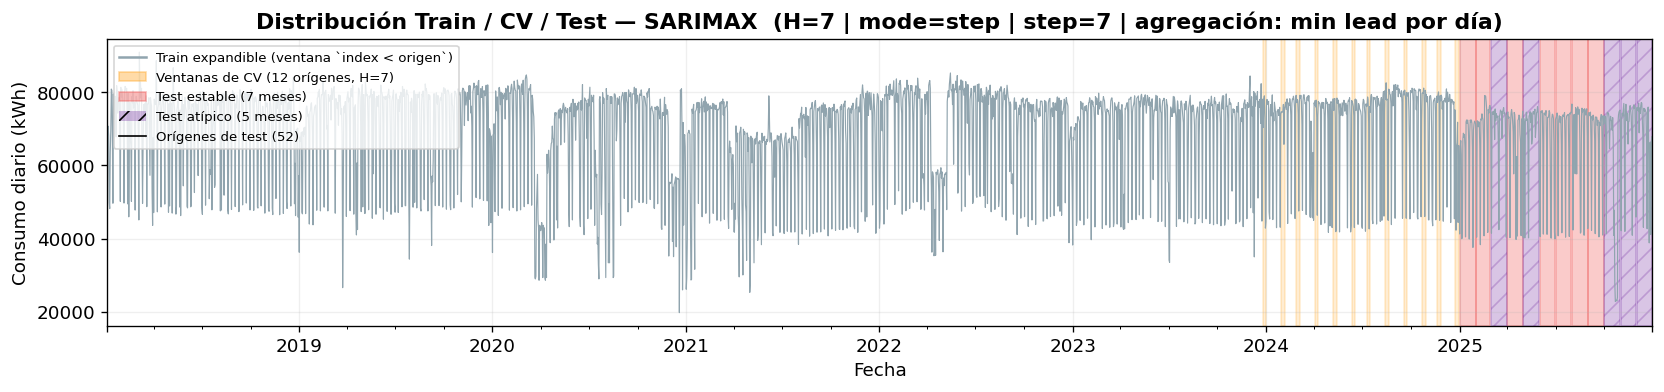

In [ ]:
def month_row_count(period):
    start = pd.Timestamp(str(period) + '-01')
    end   = start + MonthEnd(1)
    return len(df[(df.index >= start) & (df.index <= end)])

test_start   = pd.Timestamp(TEST_START + '-01')
pre_test_end = test_start - pd.Timedelta(days=1)


def atypical_fraction(start, end):
    """Fracción de los días de [start, end] que caen en ATYPICAL_MONTHS."""
    days = pd.date_range(start, end, freq='D')
    if len(days) == 0:
        return 0.0
    return float(np.isin(days.strftime('%Y-%m'), ATYPICAL_MONTHS).mean())


def generate_origins(df, start, end, h, mode="step", step=30, min_len=None):
    """
    Generador ÚNICO de orígenes (se usa para CV y para test).

    mode="step"        → orígenes cada `step` días a partir de `start` (A: step=1 ; B: step=s).
    mode="month_start" → día 1 de cada mes (>= start)                                      (C).
    Un origen `t` es válido si la ventana [t, min(t+h-1, end)] tiene al menos `min_len`
    días con datos. min_len=h  → solo ventanas COMPLETAS ("mientras la ventana de h días quepa").
    Retorna DataFrame: origin, end (último día de la ventana), n_days, atyp_frac, atypical.
    """
    start = pd.Timestamp(start); last_day = min(pd.Timestamp(end), df.index.max())
    min_len = h if min_len is None else min_len
    if mode == "step":
        cands = pd.date_range(start, last_day, freq=f"{int(step)}D")
    elif mode == "month_start":
        cands = pd.date_range(start, last_day, freq="MS")
    else:
        raise ValueError("mode debe ser 'step' o 'month_start'")
    rows = []
    for t in cands:
        w_end = min(t + pd.Timedelta(days=h - 1), last_day)
        n = int(((df.index >= t) & (df.index <= w_end)).sum())
        if n >= min_len:
            frac = atypical_fraction(t, w_end)
            rows.append({'origin': t, 'end': w_end, 'n_days': n, 'atyp_frac': frac,
                         'atypical': bool(frac > 0 and frac >= ATYPICAL_OVERLAP_THR)})
    return pd.DataFrame(rows, columns=['origin', 'end', 'n_days', 'atyp_frac', 'atypical'])


def select_evenly(frame, k):
    """Submuestrea `k` filas espaciadas uniformemente (conserva el orden)."""
    if len(frame) <= k:
        return frame.reset_index(drop=True)
    pos = np.unique(np.round(np.linspace(0, len(frame) - 1, k)).astype(int))
    return frame.iloc[pos].reset_index(drop=True)


def select_cv_origins(cands, n_folds, span_days):
    """Orígenes de CV: los últimos `span_days` días pre-test (máx. `n_folds`, submuestreo uniforme)."""
    cands = cands.sort_values('origin').reset_index(drop=True)
    if len(cands) == 0:
        raise ValueError("No hay orígenes de CV válidos (ventanas completas, estables, antes del test). "
                         "Reduce H, TRAIN_START/MIN_TRAIN_DAYS o revisa ATYPICAL_MONTHS.")
    last = cands['origin'].iloc[-1]
    sel = cands[cands['origin'] > last - pd.Timedelta(days=span_days)]
    if len(sel) < min(n_folds, len(cands)):                 # pocos en el span → alcanzar más atrás
        sel = cands.iloc[-min(n_folds, len(cands)):]
    return select_evenly(sel, n_folds)


# ── Meses de test (vistas mensuales): desde TEST_START hasta fin, con ≥ 20 días ──
p = test_start.to_period('M')
last_period = df.index.max().to_period('M')
TEST_MONTHS = []
while p <= last_period:
    if month_row_count(p) >= 20:
        TEST_MONTHS.append(str(p))
    p += 1
if not TEST_MONTHS:
    raise ValueError(f"No hay meses completos de test desde {TEST_START}. Ajusta TEST_START.")

# ── Orígenes de TEST ─────────────────────────────────────────────────────────
test_origins = generate_origins(df, test_start, df.index.max(), H, ORIGIN_MODE, STEP,
                                min_len=MIN_WINDOW_EFF)
if len(test_origins) == 0:
    raise ValueError("No hay orígenes de test válidos. Revisa H, ORIGIN_MODE/STEP, MIN_WINDOW y TEST_START.")

# ── Orígenes de CV (zona pre-test; ventanas COMPLETAS y ESTABLES) ─────────────
cv_first = pd.Timestamp(TRAIN_START + '-01') + pd.Timedelta(days=MIN_TRAIN_DAYS)
cv_all   = generate_origins(df, cv_first, pre_test_end, H, ORIGIN_MODE, STEP, min_len=H)
cv_stable_cands = cv_all[~cv_all['atypical']]
CV_ORIGINS = select_cv_origins(cv_stable_cands, N_CV_FOLDS, CV_SPAN_DAYS)

# ── Estables vs atípicos ──────────────────────────────────────────────────────
STABLE_MONTHS   = [m for m in TEST_MONTHS if m not in ATYPICAL_MONTHS]
ATYP_IN_TEST    = [m for m in TEST_MONTHS if m in ATYPICAL_MONTHS]
ANALYSIS_MONTHS = STABLE_MONTHS                                   # base de TODO promedio mensual
PLOT_MONTHS     = TEST_MONTHS if SHOW_ALL_MONTHS_IN_PLOTS else STABLE_MONTHS

STABLE_TEST_ORIGINS = test_origins[~test_origins['atypical']].reset_index(drop=True)
PERM_ORIGINS = select_evenly(STABLE_TEST_ORIGINS, PERM_MAX_ORIGINS)['origin'].tolist()  # para permutación

pre_test = df[df.index < test_start]

print("=" * 72)
print(f"  Dataset completo : {df.index.min().date()} → {df.index.max().date()}")
print(f"  Train (pre-test) : {pre_test.index.min().date()} → {pre_test.index.max().date()}  ({len(pre_test)} días)")
print(f"  Régimen          : {run_subtitle()}")
print(f"  Orígenes CV      : {len(CV_ORIGINS)}  ({CV_ORIGINS['origin'].min().date()} → {CV_ORIGINS['origin'].max().date()}), "
      f"ventanas completas de {H} d, atípicas excluidas "
      f"({int(cv_all['atypical'].sum())} de {len(cv_all)} candidatas descartadas)")
print(f"  Orígenes TEST    : {len(test_origins)}  ({test_origins['origin'].min().date()} → {test_origins['origin'].max().date()})"
      f"  | ventanas recortadas: {int((test_origins['n_days'] < H).sum())}")
print(f"     → estables {len(STABLE_TEST_ORIGINS)}  |  atípicos {int(test_origins['atypical'].sum())}"
      f"  (solape ≥ {ATYPICAL_OVERLAP_THR})")
print(f"  Meses de test ({len(TEST_MONTHS)}) : {TEST_MONTHS[0]} → {TEST_MONTHS[-1]}")
print(f"     → Estables ({len(STABLE_MONTHS)}) : {STABLE_MONTHS}")
print(f"     → Atípicos ({len(ATYP_IN_TEST)}) : {ATYP_IN_TEST}")
print(f"  Ajustes SARIMAX esperados en test: {len(test_origins)} orígenes × {len(VARIANTS)} variantes = "
      f"{len(test_origins) * len(VARIANTS)} fits")
if ORIGIN_MODE == 'step' and STEP == 1:
    print("  ⚠ Modo A (STEP=1): un fit por día de test. Recomendado: buscar hiperparámetros en C o B y usar A "
          "solo en evaluación final (RUN_TUNING=False + TUNED_PARAMS_OVERRIDE).")
print("=" * 72)
print("\nPrimeros orígenes de test:")
print(test_origins.head(8).to_string(index=False))

# ── Visualización del split ───────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 3.4))
df['Consumo'].plot(ax=ax, lw=0.7, color='#90A4AE')

for _, o in CV_ORIGINS.iterrows():
    ax.axvspan(o['origin'], o['end'] + pd.Timedelta(days=1), color='#FFA726', alpha=0.20)
for mes in STABLE_MONTHS:
    s = pd.Timestamp(f'{mes}-01'); e = s + MonthEnd(1)
    ax.axvspan(s, e, color='#EF5350', alpha=0.30)
for mes in ATYP_IN_TEST:
    s = pd.Timestamp(f'{mes}-01'); e = s + MonthEnd(1)
    ax.axvspan(s, e, color=COLOR_ATYPICAL, alpha=0.25, hatch='//')
ax.vlines(test_origins['origin'], 0, 0.07, transform=ax.get_xaxis_transform(), color='k', lw=0.8)
ax.vlines(CV_ORIGINS['origin'], 0, 0.07, transform=ax.get_xaxis_transform(), color='#E65100', lw=0.8)

handles = [Line2D([0], [0], color='#90A4AE', lw=1.5, label='Train expandible (ventana `index < origen`)'),
           Patch(color='#FFA726', alpha=0.4, label=f'Ventanas de CV ({len(CV_ORIGINS)} orígenes, H={H})'),
           Patch(color='#EF5350', alpha=0.4, label=f'Test estable ({len(STABLE_MONTHS)} meses)'),
           Patch(facecolor=COLOR_ATYPICAL, alpha=0.3, hatch='//', label=f'Test atípico ({len(ATYP_IN_TEST)} meses)'),
           Line2D([0], [0], color='k', lw=1, label=f'Orígenes de test ({len(test_origins)})')]
ax.legend(handles=handles, loc='upper left', fontsize=8)
ax.set_title(f'Distribución Train / CV / Test — SARIMAX  ({run_subtitle()})', fontweight='bold')
ax.set_ylabel('Consumo diario (kWh)'); ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig(f'split_overview_sarimax_{RUN_TAG}.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Funciones auxiliares

- `compute_metrics`: MAE, RMSE, MAPE (%), R² (idénticas al original).
- `fit_predict_sarimax`: ajusta un SARIMAX (pmdarima) con exógenas y predice `n_periods = len(y_te)` (**siempre la longitud
  real de la ventana de ese origen, ≤ H**).
- `cv_score_sarimax`: walk-forward CV sobre **orígenes** `CV_ORIGINS`; retorna **media, std y mediana** del MAPE por ventana.
- `evaluate_origins`: ajusta/predice para una tabla de orígenes y devuelve la tabla larga de predicciones
  (`origin, lead, Fecha, Mes, real, pred…`) y el detalle por origen.
- `aggregate_min_lead` / `build_monthly`: construyen la **serie mensual** con la política *min lead por día*.
- `lead_curve`: error medio por **lead time 1…H** sobre ventanas estables.

In [ ]:
def compute_metrics(y_true, y_pred):
    """Calcula MAE, RMSE, MAPE y R² (idéntico al notebook original)."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mask = y_true != 0
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    r2   = r2_score(y_true, y_pred)
    return {'MAE': round(mae, 2), 'RMSE': round(rmse, 2),
            'MAPE (%)': round(mape, 4), 'R²': round(r2, 4)}

NAN_METRICS = {'MAE': np.nan, 'RMSE': np.nan, 'MAPE (%)': np.nan, 'R²': np.nan}


def fit_predict_sarimax(order, seasonal_order, y_tr, X_tr, y_te, X_te):
    """
    Ajusta un SARIMAX (pmdarima) con variables exógenas y retorna las predicciones sobre
    la ventana objetivo junto con el objeto modelo ajustado. Suprime warnings de convergencia.
    n_periods = len(y_te)  →  alineado con la longitud REAL de la ventana (≤ H).
    """
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        try:
            m = PmARIMA(order=order, seasonal_order=seasonal_order)
            m.fit(y_tr, X=X_tr)
            preds = m.predict(n_periods=len(y_te), X=X_te)
            return np.asarray(preds, dtype=float), m
        except Exception as e:
            print(f"    ⚠ Error en SARIMAX {order} / {seasonal_order}: {e}")
            return np.full(len(y_te), np.nan), None


def get_exog_coefs(model, exog_cols):
    """Extrae los coeficientes de las variables exógenas por NOMBRE desde el objeto
    statsmodels ajustado (no por posición)."""
    if model is None or not hasattr(model, 'arima_res_'):
        return None
    try:
        res = model.arima_res_
        names = list(res.param_names)
        params = np.asarray(res.params)
        coefs = {col: float(params[names.index(col)]) for col in exog_cols if col in names}
        return coefs if coefs else None
    except Exception:
        return None


def cv_score_sarimax(order, seasonal_order, cv_origins, trial=None):
    """
    Walk-forward CV sobre ORÍGENES dentro del train. Para cada origen t: entrena en todo lo
    anterior (ventana expandible) y predice la ventana [t, t+H-1]. Retorna dict con
    'mean' (criterio de selección), 'std', 'median', 'folds' (MAPE por ventana).
    Si se pasa `trial` (Optuna), reporta la media acumulada fold a fold y habilita el PRUNING.
    """
    mapes = []
    for step_i, (_, o) in enumerate(cv_origins.iterrows()):
        t, e = o['origin'], o['end']
        tr  = df[df.index < t]
        val = df[(df.index >= t) & (df.index <= e)]
        if len(tr) < MIN_TRAIN_DAYS or len(val) == 0:
            continue
        y_tr, X_tr = tr[TARGET], tr[EXOG_COLS]
        y_v,  X_v  = val[TARGET], val[EXOG_COLS]
        preds, _ = fit_predict_sarimax(order, seasonal_order, y_tr, X_tr, y_v, X_v)
        if not np.all(np.isnan(preds)):
            mapes.append(compute_metrics(y_v.values, preds)['MAPE (%)'])
        else:
            mapes.append(999.0)
        # ── Pruning de Optuna: reporta media acumulada y corta si should_prune() ──
        if trial is not None:
            trial.report(float(np.mean(mapes)), step_i)
            if trial.should_prune():
                raise optuna.TrialPruned()
    mapes = np.array(mapes, dtype=float)
    if len(mapes) == 0:
        return {'mean': 999.0, 'std': 0.0, 'median': 999.0, 'folds': []}
    return {'mean': float(np.mean(mapes)),
            'std':  float(np.std(mapes, ddof=1)) if len(mapes) > 1 else 0.0,
            'median': float(np.median(mapes)),
            'folds': mapes.tolist()}


def evaluate_origins(origins, params_by_variant, keep_models_for=(), desc='Evaluando orígenes'):
    """
    Para cada origen: entrena con `index < origin` y predice [origin, end] con cada variante.
    Retorna:
      preds_long : DataFrame largo (origin, variant, lead, Fecha, Mes, real, pred, window_atyp)
      per_origin : dict origin -> {'info': ..., variante: {preds, real, dates, X_test, metrics, model, coefs}}
                   (el modelo ajustado solo se conserva en `keep_models_for`, para ahorrar memoria).
    """
    keep = set(pd.to_datetime(list(keep_models_for)))
    parts, per_origin = [], {}
    for _, o in tqdm(list(origins.iterrows()), desc=desc):
        t, e = o['origin'], o['end']
        train = df[df.index < t]
        test  = df[(df.index >= t) & (df.index <= e)]
        y_tr, X_tr = train[TARGET], train[EXOG_COLS]
        y_te, X_te = test[TARGET],  test[EXOG_COLS]
        per_origin[t] = {'info': o.to_dict()}
        for variant, params in params_by_variant.items():
            preds, model = fit_predict_sarimax(params['order'], params['seasonal_order'],
                                               y_tr, X_tr, y_te, X_te)
            ok = not np.all(np.isnan(preds))
            metrics = compute_metrics(y_te.values, preds) if ok else dict(NAN_METRICS)
            per_origin[t][variant] = {
                'preds': preds, 'real': y_te.values, 'dates': y_te.index, 'X_test': X_te,
                'metrics': metrics,
                'model': model if (t in keep and variant == 'tuned') else None,
                'coefs': get_exog_coefs(model, EXOG_COLS) if variant == 'tuned' else None}
            parts.append(pd.DataFrame({
                'origin': t, 'variant': variant, 'lead': np.arange(1, len(test) + 1),
                'Fecha': test.index, 'Mes': test.index.strftime('%Y-%m'),
                'real': y_te.values, 'pred': preds, 'window_atyp': bool(o['atypical'])}))
    preds_long = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(
        columns=['origin', 'variant', 'lead', 'Fecha', 'Mes', 'real', 'pred', 'window_atyp'])
    return preds_long, per_origin


def aggregate_min_lead(preds_long):
    """POLÍTICA DE AGREGACIÓN: si un día d lo predicen varios orígenes, se usa el del MENOR lead
    (= origen más reciente con origen ≤ d). Una fila por (variante, Fecha)."""
    d = preds_long.sort_values(['variant', 'Fecha', 'lead'])
    return d.drop_duplicates(['variant', 'Fecha'], keep='first').reset_index(drop=True)


def build_monthly(preds_long, months, variants=None):
    """Serie predicha por MES CALENDARIO de test (agregación min-lead). Los días sin predicción
    quedan NaN. Devuelve dict[mes][variante] = dates, real, preds, lead, n_cov, metrics, mean_lead."""
    variants = variants or list(preds_long['variant'].unique())
    agg = aggregate_min_lead(preds_long)
    out = {}
    for mes in months:
        s = pd.Timestamp(f'{mes}-01'); e = s + MonthEnd(1)
        days = df.index[(df.index >= s) & (df.index <= e)]
        real = df.loc[days, TARGET].to_numpy(float)
        out[mes] = {}
        for variant in variants:
            a = agg[(agg['variant'] == variant) & (agg['Mes'] == mes)].set_index('Fecha')
            preds = a['pred'].reindex(days).to_numpy(float)
            leads = a['lead'].reindex(days).to_numpy(float)
            valid = ~np.isnan(preds) & ~np.isnan(real)
            n = int(valid.sum())
            metrics = compute_metrics(real[valid], preds[valid]) if n >= MIN_MONTH_COVER_DAYS else dict(NAN_METRICS)
            out[mes][variant] = {'dates': days, 'real': real, 'preds': preds, 'lead': leads,
                                 'n_cov': n, 'metrics': metrics,
                                 'mean_lead': float(np.nanmean(leads[valid])) if n else np.nan}
    return out


def lead_curve(preds_long, h, only_stable=True):
    """Error medio por LEAD TIME 1…h (promedio sobre ventanas estables): |error| (kWh) y APE (%)."""
    d = preds_long.dropna(subset=['pred', 'real']).copy()
    if only_stable:
        d = d[~d['window_atyp']]
    d['abs_err'] = (d['real'] - d['pred']).abs()
    d['ape'] = np.where(d['real'] != 0, d['abs_err'] / d['real'].replace(0, np.nan) * 100, np.nan)
    g = d.groupby(['variant', 'lead']).agg(mae=('abs_err', 'mean'), ape=('ape', 'mean'),
                                           n=('abs_err', 'size')).reset_index()
    full = pd.MultiIndex.from_product([sorted(d['variant'].unique()), range(1, h + 1)],
                                      names=['variant', 'lead'])
    return g.set_index(['variant', 'lead']).reindex(full).reset_index()


print("✓ Funciones auxiliares definidas.")

✓ Funciones auxiliares definidas.


## 7. Búsqueda guiada de hiperparámetros (warm-started desde el mejor SARIMAX conocido)

Igual que en el original: se parte de la **estructura del mejor SARIMAX conocido** (`BEST_KNOWN_SARIMAX`) y se explora solo
su **vecindario** con **Optuna (TPE)** + **`MedianPruner`**. El primer trial es **exactamente** `BEST_KNOWN_SARIMAX`
(`enqueue_trial`), así el resultado **nunca es peor** que el punto de partida.

**Cambio:** el criterio es el **MAPE medio de walk-forward sobre las ventanas de `H` días** de los orígenes de CV
(`CV_ORIGINS`, ≤ `N_CV_FOLDS`); se reportan también **std** y **mediana**.

> Si `RUN_TUNING=False` (p. ej. modo A) se omite la búsqueda y se usa `TUNED_PARAMS_OVERRIDE` (o `BEST_KNOWN_SARIMAX`).

In [ ]:
# Espacio de búsqueda: vecindario discreto y pequeño alrededor de BEST_KNOWN_SARIMAX
SPACE = {
    'p': [1, 2, 3, 4],
    'd': [0, 1],
    'q': [0, 1, 2],
    'P': [0, 1, 2],
    'D': [0, 1],
    'Q': [1, 2, 3],
}

def _order_from(raw):
    return (int(raw['p']), int(raw['d']), int(raw['q'])), (int(raw['P']), int(raw['D']), int(raw['Q']), SEASONAL_M)

def _encode_known(best_known):
    o, so = best_known['order'], best_known['seasonal_order']
    return {'p': o[0], 'd': o[1], 'q': o[2], 'P': so[0], 'D': so[1], 'Q': so[2]}

tuning_rows = []
t0 = time.time()

if not RUN_TUNING:
    best_params_sarimax = dict(TUNED_PARAMS_OVERRIDE or BEST_KNOWN_SARIMAX)
    best_stats  = {'mean': np.nan, 'std': np.nan, 'median': np.nan}
    known_stats = {'mean': np.nan, 'std': np.nan, 'median': np.nan}
    print(f"RUN_TUNING=False → sin búsqueda. Parámetros 'tuned' fijados: {best_params_sarimax}")

elif HAS_OPTUNA:
    def objective(trial):
        raw = {k: trial.suggest_categorical(k, v) for k, v in SPACE.items()}
        order, seasonal_order = _order_from(raw)
        trial.set_user_attr('order', order)
        trial.set_user_attr('seasonal_order', seasonal_order)
        cvs = cv_score_sarimax(order, seasonal_order, CV_ORIGINS, trial=trial)
        trial.set_user_attr('cv_std', cvs['std'])
        trial.set_user_attr('cv_median', cvs['median'])
        return cvs['mean']

    study = optuna.create_study(
        direction='minimize',
        sampler=optuna.samplers.TPESampler(seed=SEED),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3))
    study.enqueue_trial(_encode_known(BEST_KNOWN_SARIMAX))     # trial 1 = mejor conocido (warm-start)

    for it in tqdm(range(N_TRIALS), desc='SARIMAX Optuna'):
        study.optimize(objective, n_trials=1, catch=(Exception,))
        t = study.trials[-1]
        is_pruned = (t.state == optuna.trial.TrialState.PRUNED)
        order = t.user_attrs.get('order'); seasonal_order = t.user_attrs.get('seasonal_order')
        tuning_rows.append({'trial': it+1, 'cv_mape': t.value,
                            'cv_std': t.user_attrs.get('cv_std'),
                            'cv_median': t.user_attrs.get('cv_median'),
                            'pruned': bool(is_pruned),
                            'order': order, 'seasonal_order': seasonal_order})
        if (it+1) % 5 == 0 or (it+1) == N_TRIALS:
            best = study.best_value if study.best_trial else float('nan')
            vtxt = f"{t.value:.3f}%" if t.value is not None else "pruned "
            print(f"  trial {it+1:>3}/{N_TRIALS}  MAPE={vtxt}  mejor={best:.3f}%  t={time.time()-t0:.0f}s")

    bt = study.best_trial
    best_order = bt.user_attrs['order']; best_seasonal = bt.user_attrs['seasonal_order']
    best_params_sarimax = {'order': best_order, 'seasonal_order': best_seasonal}
    best_stats  = {'mean': bt.value, 'std': bt.user_attrs['cv_std'], 'median': bt.user_attrs['cv_median']}
    k0 = study.trials[0]
    known_stats = {'mean': k0.value, 'std': k0.user_attrs['cv_std'], 'median': k0.user_attrs['cv_median']}

else:
    def _sample_local():
        raw = {k: rng.choice(v) for k, v in SPACE.items()}
        return _order_from(raw)
    order0, seasonal0 = _order_from(_encode_known(BEST_KNOWN_SARIMAX))
    cands = [(order0, seasonal0)] + [_sample_local() for _ in range(N_TRIALS - 1)]
    best_params_sarimax, best_stats, known_stats = None, {'mean': np.inf}, None
    for it, (order, seasonal_order) in enumerate(tqdm(cands, desc='SARIMAX local')):
        cvs = cv_score_sarimax(order, seasonal_order, CV_ORIGINS)
        tuning_rows.append({'trial': it+1, 'cv_mape': cvs['mean'],
                            'cv_std': cvs['std'], 'cv_median': cvs['median'],
                            'pruned': False, 'order': order, 'seasonal_order': seasonal_order})
        if it == 0:
            known_stats = {'mean': cvs['mean'], 'std': cvs['std'], 'median': cvs['median']}
        if cvs['mean'] < best_stats['mean']:
            best_stats = {'mean': cvs['mean'], 'std': cvs['std'], 'median': cvs['median']}
            best_params_sarimax = {'order': order, 'seasonal_order': seasonal_order}
        if (it+1) % 5 == 0 or (it+1) == len(cands):
            print(f"  trial {it+1:>3}/{len(cands)}  MAPE={cvs['mean']:.3f}%  "
                  f"mejor={best_stats['mean']:.3f}%  t={time.time()-t0:.0f}s")

tuning_df = pd.DataFrame(tuning_rows, columns=['trial', 'cv_mape', 'cv_std', 'cv_median',
                                               'pruned', 'order', 'seasonal_order'])
mejora = known_stats['mean'] - best_stats['mean']

print(f"\n{'='*66}")
print(f"  Criterio: MAPE medio walk-forward sobre ventanas de H={H} d ({len(CV_ORIGINS)} orígenes CV)")
print(f"  Búsqueda completada en {(time.time()-t0)/60:.1f} min")
print(f"  Best-known : MAPE CV = {known_stats['mean']:.3f}%  "
      f"(std {known_stats['std']:.3f} | mediana {known_stats['median']:.3f})")
print(f"  Tuneado    : MAPE CV = {best_stats['mean']:.3f}%  "
      f"(std {best_stats['std']:.3f} | mediana {best_stats['median']:.3f})")
print(f"  Mejora vs best-known: {mejora:+.3f} pp de MAPE")
print(f"  Params tuneados (final): {best_params_sarimax}")
print(f"{'='*66}")

RUN_TUNING=False → sin búsqueda. Parámetros 'tuned' fijados: {'order': (3, 0, 0), 'seasonal_order': (1, 0, 2, 7)}

  Criterio: MAPE medio walk-forward sobre ventanas de H=7 d (12 orígenes CV)
  Búsqueda completada en 0.0 min
  Best-known : MAPE CV = nan%  (std nan | mediana nan)
  Tuneado    : MAPE CV = nan%  (std nan | mediana nan)
  Mejora vs best-known: +nan pp de MAPE
  Params tuneados (final): {'order': (3, 0, 0), 'seasonal_order': (1, 0, 2, 7)}


## 8. Convergencia de la búsqueda

In [ ]:
# Los trials pruned conservan un MAPE parcial: se marcan por la columna 'pruned',
# y el mínimo acumulado se calcula SOLO con los trials completados (los elegibles como mejor).
if len(tuning_df) == 0:
    print("Sin historial de búsqueda (RUN_TUNING=False): se omite la gráfica de convergencia.")
else:
    tsort = tuning_df.sort_values('trial')
    comp  = tsort[(~tsort['pruned'].fillna(False)) & tsort['cv_mape'].notna()].copy()
    prun  = tsort[tsort['pruned'].fillna(False) & tsort['cv_mape'].notna()].copy()
    comp['best_so_far'] = comp['cv_mape'].cummin()

    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    ax.scatter(comp['trial'], comp['cv_mape'], color=SARIMAX_COLOR, alpha=0.6, s=45, zorder=3, label='Trials completados')
    if len(prun):
        ax.scatter(prun['trial'], prun['cv_mape'], marker='x', color='gray',
                   s=45, alpha=0.75, zorder=3, label='Pruned (cortados)')
    ax.plot(comp['trial'], comp['best_so_far'], 'k--', lw=1.6, label='Mínimo acumulado (completados)')
    w1 = tsort[tsort['trial'] == 1]
    ax.scatter(w1['trial'], w1['cv_mape'], color='#FB8C00', s=110, zorder=5,
               edgecolor='k', label='Warm-start (trial 1)')
    ax.axhline(known_stats['mean'], color='#FB8C00', lw=1.3, ls=':', label=f"Best-known ({known_stats['mean']:.2f}%)")
    ax.axhline(best_stats['mean'],  color='red',     lw=1.2, ls=':', label=f"Tuneado ({best_stats['mean']:.2f}%)")
    ax.set_xlabel('Trial'); ax.set_ylabel(f'MAPE CV (%) — ventanas de {H} d')
    ax.set_title(f'Convergencia de la búsqueda guiada — SARIMAX\n{run_subtitle()}', fontweight='bold', fontsize=11)
    ax.legend(fontsize=8); ax.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.savefig(f'tuning_convergencia_sarimax_{RUN_TAG}.png', dpi=150, bbox_inches='tight')
    plt.show()

print("── Hiperparámetros ──")
print(f"  Default : {DEFAULT_SARIMAX}")
print(f"  Tuneado : {best_params_sarimax}")

Sin historial de búsqueda (RUN_TUNING=False): se omite la gráfica de convergencia.
── Hiperparámetros ──
  Default : {'order': (2, 1, 2), 'seasonal_order': (1, 0, 1, 7)}
  Tuneado : {'order': (3, 0, 0), 'seasonal_order': (1, 0, 2, 7)}


## 9. Evaluación final en test — Default vs Tuneado

Para **cada origen de test** `t` se entrena SARIMAX con **todo el train anterior a `t`** (ventana expandible), en dos
variantes: **default** (`DEFAULT_SARIMAX`) y **tuneado** (`best_params_sarimax`), y se predice `[t, t+H-1]` (recortada
si no hay datos). Con esto se construyen:

* `preds_long`: tabla larga (origen, lead, Fecha, Mes, real, pred) — base de degradación, exportación y agregaciones.
* `results[mes][variante]`: **serie mensual** por agregación *min lead por día* (base de las vistas mensuales).
* `per_origin[origen]`: métricas por ventana (MAPE de la ventana de `H` días), coeficientes y modelos (solo `PERM_ORIGINS`).

In [ ]:
params_by_variant = {'default': DEFAULT_SARIMAX, 'tuned': best_params_sarimax}
t_eval = time.time()
preds_long, per_origin = evaluate_origins(test_origins, params_by_variant,
                                          keep_models_for=PERM_ORIGINS, desc='Test (default + tuned)')
results = build_monthly(preds_long, TEST_MONTHS, VARIANTS)     # results[mes][variante] (vista mensual)

print(f"\n✓ Evaluación completa: {len(test_origins)} orígenes × {len(VARIANTS)} variantes "
      f"en {(time.time()-t_eval)/60:.1f} min")
print(f"  Política mensual: {AGG_POLICY}  |  filas de predicción: {len(preds_long):,}")

# Métricas POR VENTANA (origen): MAPE de cada ventana de H días
origin_rows = []
for t, r in per_origin.items():
    for variant in VARIANTS:
        origin_rows.append({'Origen': t.date(), 'Fin ventana': r['info']['end'].date(),
                            'Días': int(r['info']['n_days']), 'Frac. atípica': round(r['info']['atyp_frac'], 3),
                            'Atípico': bool(r['info']['atypical']), 'Variante': variant, **r[variant]['metrics']})
origin_metrics_df = pd.DataFrame(origin_rows)

Test (default + tuned):   0%|          | 0/52 [00:00<?, ?it/s]


✓ Evaluación completa: 52 orígenes × 2 variantes en 51.5 min
  Política mensual: min lead por día  |  filas de predicción: 728


## 10. Predicción vs Real — Default vs Tuneado (un panel por mes calendario)

**Layout idéntico al original: un panel por mes calendario de test.** Pero cada curva predicha se construye con la
**política `min lead por día`** a partir de ventanas de `H` días con el régimen de orígenes elegido (A/B/C). Por eso
cada panel lleva el subtítulo `Mes | H | mode | step | agregación`. Las marcas `|` en la base del panel indican los
**orígenes** cuyo origen cae en ese mes. Los días sin predicción que los cubra **no se grafican** (`NaN`). Los meses
atípicos van marcados con **⚠** y **no entran** en los promedios.

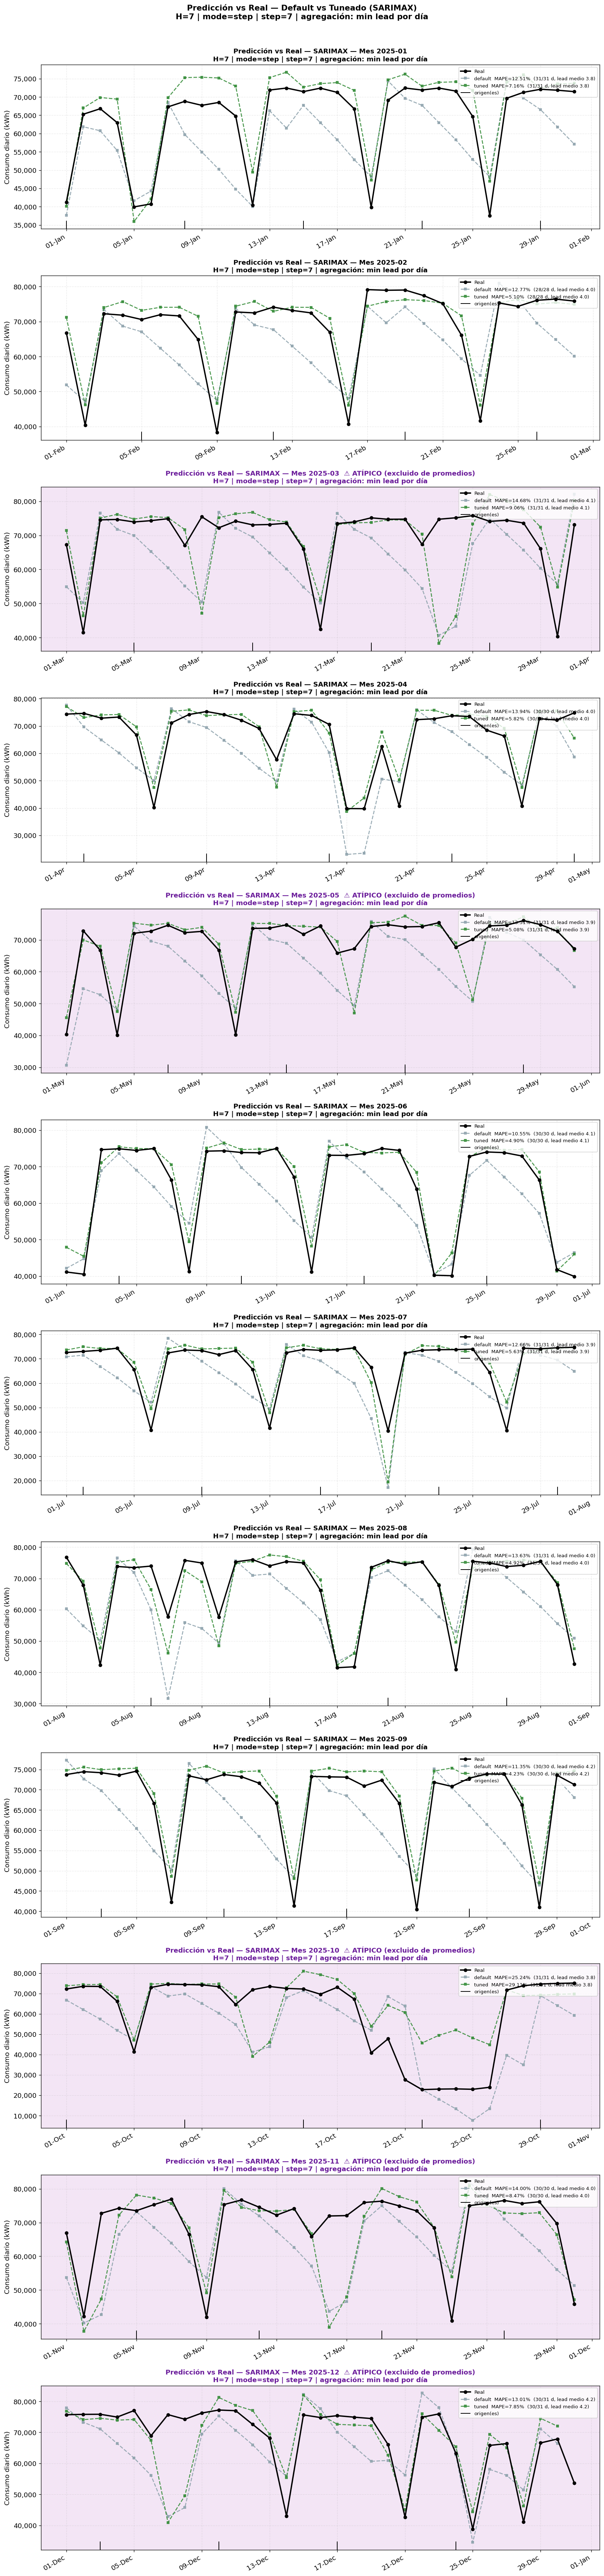

In [ ]:
n = len(PLOT_MONTHS)
fig, axes = plt.subplots(n, 1, figsize=(14, 4.9*n), sharex=False)
if n == 1: axes = [axes]

for ax, mes in zip(axes, PLOT_MONTHS):
    dates = results[mes]['tuned']['dates']
    real  = results[mes]['tuned']['real']
    ax.plot(dates, real, 'k-o', lw=2.2, ms=5, label='Real', zorder=6)
    for variant in VARIANTS:
        rv   = results[mes][variant]
        mape = rv['metrics']['MAPE (%)']
        mape_txt = f"{mape:.2f}%" if not np.isnan(mape) else "n/d"
        ax.plot(dates, rv['preds'], '--s', ms=4, lw=1.6, color=VCOLORS[variant], alpha=0.9,
                label=f"{variant}  MAPE={mape_txt}  ({rv['n_cov']}/{len(dates)} d, lead medio {rv['mean_lead']:.1f})"
                      if rv['n_cov'] else f"{variant}  (sin cobertura)")
    org_mes = [o for o in test_origins['origin'] if o.strftime('%Y-%m') == mes]
    if org_mes:
        ax.vlines(org_mes, 0, 0.05, transform=ax.get_xaxis_transform(), color='k', lw=1.2, label='origen(es)')
    tag = '  ⚠ ATÍPICO (excluido de promedios)' if is_atyp(mes) else ''
    ax.set_title(f'Predicción vs Real — SARIMAX — Mes {mes}{tag}\n{run_subtitle()}',
                 fontsize=11, fontweight='bold', color=(COLOR_ATYPICAL if is_atyp(mes) else 'black'))
    ax.set_ylabel('Consumo diario (kWh)')
    ax.legend(loc='upper right', fontsize=8); ax.grid(True, alpha=0.25, ls='--')
    if is_atyp(mes): ax.set_facecolor('#F3E5F5')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

plt.suptitle(f'Predicción vs Real — Default vs Tuneado (SARIMAX)\n{run_subtitle()}',
             fontsize=13, fontweight='bold', y=1.005)
plt.tight_layout()
plt.savefig(f'pred_vs_real_sarimax_{RUN_TAG}.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Degradación del error con el horizonte — Default vs Tuneado (lead time 1…H)

**Eje X = lead time `1, 2, …, H`** (definido por el parámetro `H` de la corrida; no es el día del mes).
**Eje Y** = error absoluto medio (kWh) y APE medio (%) en cada lead, **promediado sobre las ventanas estables**
(no atípicas) de test. Las líneas tenues son las curvas de cada ventana (si son pocas). Con orígenes que se solapan
(B/A) cada lead se promedia sobre muchas ventanas; con ventanas recortadas al final de los datos, los leads altos
tienen menos ventanas (`n` en el subtítulo).

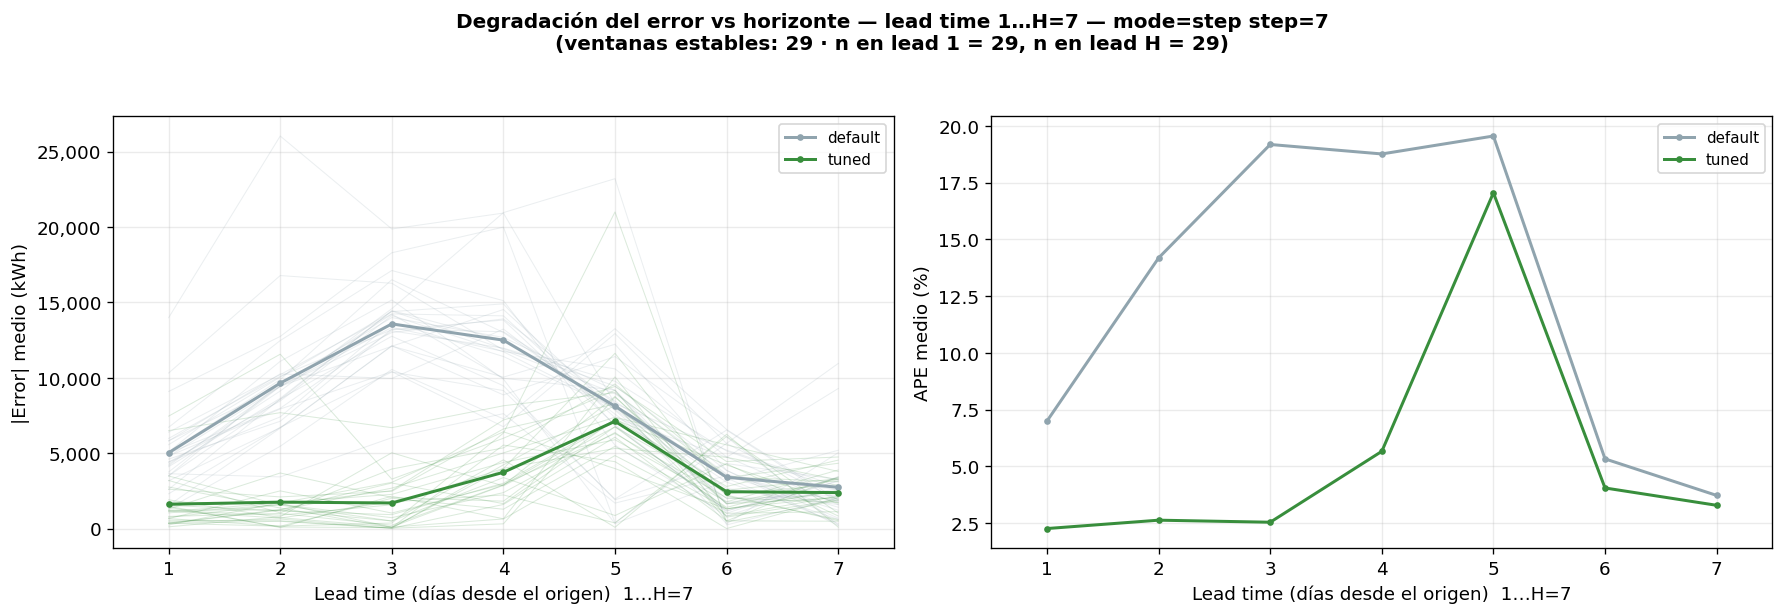

In [ ]:
lc = lead_curve(preds_long, H, only_stable=True)
n_stable_win = len(STABLE_TEST_ORIGINS)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.9))
for ax, (col, ylab) in zip(axes, [('mae', '|Error| medio (kWh)'), ('ape', 'APE medio (%)')]):
    for variant in VARIANTS:
        g = lc[lc['variant'] == variant]
        ax.plot(g['lead'], g[col], '-o', ms=3, lw=1.8, color=VCOLORS[variant], label=variant, zorder=4)
    ax.set_xlabel(f'Lead time (días desde el origen)  1…H={H}'); ax.set_ylabel(ylab)
    ax.set_xlim(0.5, H + 0.5); ax.legend(fontsize=9); ax.grid(True, alpha=0.25)
    if col == 'mae':
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
# curvas individuales por ventana estable (contexto), solo si son pocas
if n_stable_win <= 60:
    for t in STABLE_TEST_ORIGINS['origin']:
        for variant in VARIANTS:
            r = per_origin[t][variant]
            ae = np.abs(np.asarray(r['real'], float) - np.asarray(r['preds'], float))
            axes[0].plot(np.arange(1, len(ae) + 1), ae, '-', lw=0.6, alpha=0.18, color=VCOLORS[variant], zorder=1)
n_lead1 = int(lc[(lc['variant'] == 'tuned') & (lc['lead'] == 1)]['n'].fillna(0).iloc[0]) if 'tuned' in set(lc['variant']) else 0
n_leadH = int(lc[(lc['variant'] == 'tuned') & (lc['lead'] == H)]['n'].fillna(0).iloc[0]) if 'tuned' in set(lc['variant']) else 0
plt.suptitle(f'Degradación del error vs horizonte — lead time 1…H={H} — mode={ORIGIN_MODE} step={STEP_TXT}\n'
             f'(ventanas estables: {n_stable_win} · n en lead 1 = {n_lead1}, n en lead H = {n_leadH})',
             fontsize=12, fontweight='bold', y=1.04)
plt.tight_layout()
plt.savefig(f'error_horizonte_sarimax_{RUN_TAG}.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Tabla comparativa — Default vs Tuneado

* **Por mes calendario** (agregación *min lead por día*): incluye `Días cubiertos` y `Lead medio` para saber qué tan
  "lejos" fueron predichos los días de ese mes.
* **Por ventana (origen)**: MAPE de cada ventana de `H` días (`origin_metrics_df`).

In [ ]:
def _avg_metrics(variant, meses):
    return pd.DataFrame([results[m][variant]['metrics'] for m in meses]).mean()

rows = []
for mes in TEST_MONTHS:
    for variant in VARIANTS:
        rv = results[mes][variant]
        rows.append({'Mes': mes, 'Atípico': is_atyp(mes), 'Variante': variant,
                     'Días cubiertos': rv['n_cov'], 'Lead medio': round(rv['mean_lead'], 1) if rv['n_cov'] else np.nan,
                     **rv['metrics']})
metrics_df = pd.DataFrame(rows)

print(f"══ Métricas por mes calendario (default vs tuned) — {run_subtitle()} ══")
print(metrics_df.to_string(index=False))

print("\n── Promedio sobre meses ESTABLES ──")
for variant in VARIANTS:
    a = _avg_metrics(variant, STABLE_MONTHS)
    print(f"  {variant:8s}: MAE={a['MAE']:,.0f}  RMSE={a['RMSE']:,.0f}  "
          f"MAPE={a['MAPE (%)']:.2f}%  R²={a['R²']:.4f}")

print("\n══ Métricas por VENTANA de H días (origen) — promedio sobre ventanas estables ══")
_ws = origin_metrics_df[~origin_metrics_df['Atípico']]
print(_ws.groupby('Variante')[['MAE', 'RMSE', 'MAPE (%)', 'R²']].mean().round(3).to_string())

══ Métricas por mes calendario (default vs tuned) — H=7 | mode=step | step=7 | agregación: min lead por día ══
    Mes  Atípico Variante  Días cubiertos  Lead medio      MAE     RMSE  MAPE (%)      R²
2025-01    False  default              31         3.8  7946.56  9394.75   12.5080  0.3819
2025-01    False    tuned              31         3.8  4129.54  4883.44    7.1635  0.8330
2025-02    False  default              28         4.0  8211.47  9283.91   12.7725  0.4080
2025-02    False    tuned              28         4.0  2967.96  3605.26    5.1020  0.9107
2025-03     True  default              31         4.1  9914.32 12698.22   14.6846 -0.7046
2025-03     True    tuned              31         4.1  5964.05 10724.75    9.0647 -0.2159
2025-04    False  default              30         4.0  8304.40  9527.29   13.9423  0.3892
2025-04    False    tuned              30         4.0  3335.48  4320.85    5.8212  0.8744
2025-05     True  default              31         3.9  8967.45 10369.62   13.51

## 13. Comparativa visual — MAPE por mes estable (Default vs Tuneado)

MAPE del mes calendario calculado sobre los días cubiertos con la serie agregada *min lead por día*.

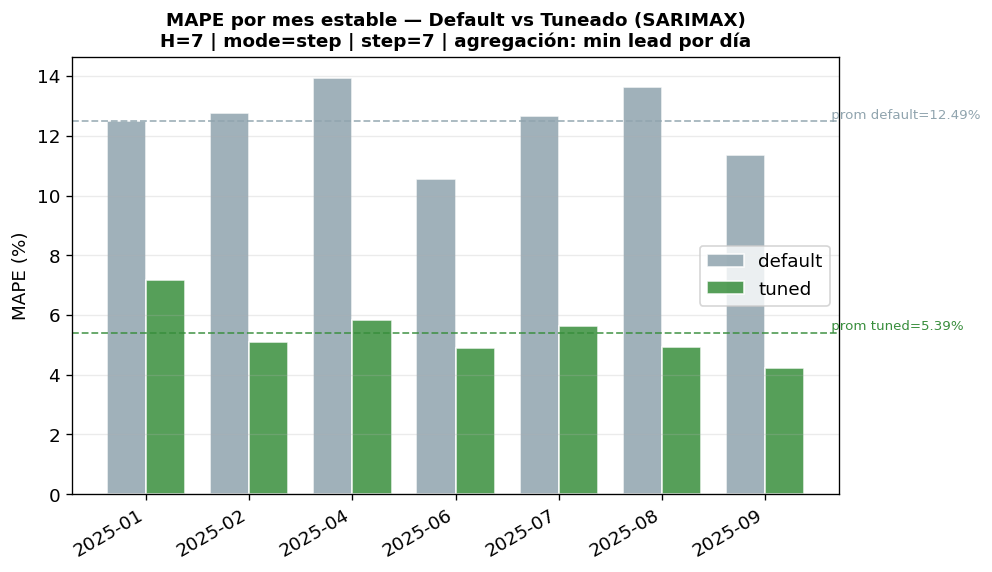

In [ ]:
stable = STABLE_MONTHS
x = np.arange(len(stable)); w = 0.38
fig, ax = plt.subplots(figsize=(max(7, len(stable)*1.2), 4.9))
for k, variant in enumerate(VARIANTS):
    vals = [results[m][variant]['metrics']['MAPE (%)'] for m in stable]
    ax.bar(x + (k-0.5)*w, vals, w, color=VCOLORS[variant], alpha=0.85, label=variant, edgecolor='white')
    avg = float(np.nanmean(vals)) if np.any(~np.isnan(vals)) else np.nan
    ax.axhline(avg, color=VCOLORS[variant], ls='--', lw=1.1, alpha=0.8)
    ax.text(len(stable)-0.4, avg, f' prom {variant}={avg:.2f}%', va='bottom',
            fontsize=8, color=VCOLORS[variant])
ax.set_xticks(x); ax.set_xticklabels(stable, rotation=30, ha='right')
ax.set_ylabel('MAPE (%)')
ax.set_title(f'MAPE por mes estable — Default vs Tuneado (SARIMAX)\n{run_subtitle()}',
             fontweight='bold', fontsize=11)
ax.legend(); ax.grid(True, axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig(f'comparativa_mape_sarimax_{RUN_TAG}.png', dpi=150, bbox_inches='tight')
plt.show()

## 14. Heatmap MAPE — mes × variante

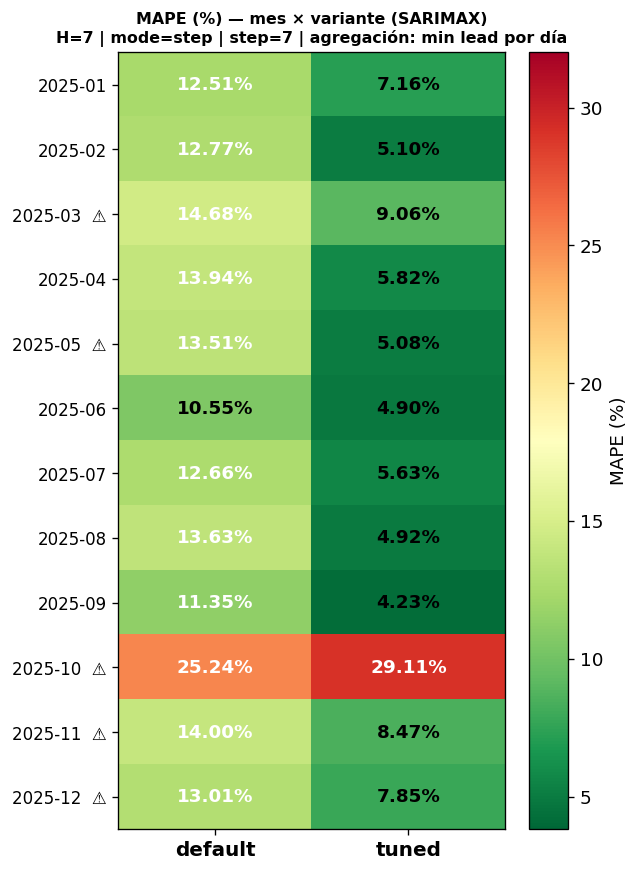

In [ ]:
mat = np.array([[results[m][v]['metrics']['MAPE (%)'] for v in VARIANTS] for m in TEST_MONTHS])
fig, ax = plt.subplots(figsize=(5.4, max(4, len(TEST_MONTHS)*0.5 + 1.4)))
im = ax.imshow(mat, cmap='RdYlGn_r', aspect='auto',
               vmin=np.nanmin(mat)*0.9, vmax=np.nanmax(mat)*1.1)
ax.set_xticks(range(len(VARIANTS))); ax.set_xticklabels(VARIANTS, fontsize=12, fontweight='bold')
ylabels = [f'{m}  ⚠' if is_atyp(m) else m for m in TEST_MONTHS]
ax.set_yticks(range(len(TEST_MONTHS))); ax.set_yticklabels(ylabels, fontsize=10)
mean_val = np.nanmean(mat)
for i in range(len(TEST_MONTHS)):
    for j in range(len(VARIANTS)):
        v = mat[i, j]
        txt = f'{v:.2f}%' if not np.isnan(v) else 'N/A'
        ax.text(j, i, txt, ha='center', va='center', fontweight='bold',
                fontsize=11, color='white' if (not np.isnan(v) and v > mean_val) else 'black')
plt.colorbar(im, ax=ax, label='MAPE (%)')
ax.set_title(f'MAPE (%) — mes × variante (SARIMAX)\n{run_subtitle()}', fontweight='bold', fontsize=9.5)
plt.tight_layout()
plt.savefig(f'heatmap_mape_sarimax_{RUN_TAG}.png', dpi=150, bbox_inches='tight')
plt.show()

## 15. Importancia de variables exógenas — SARIMAX tuneado
- **A. Coeficientes exógenos por nombre**: extraídos del objeto `statsmodels` ajustado (`arima_res_.param_names/.params`)
  buscando **cada columna de `EXOG_COLS` por su nombre exacto**. Se promedia el valor absoluto sobre las **ventanas estables**
  de test (un ajuste por origen).
- **B. Importancia por permutación (out-of-sample)**: para cada exógena se baraja su columna en la **ventana de `H` días**
  de cada origen, se re-predice con el **mismo modelo ya ajustado** (sin reentrenar) y se mide el aumento del MAPE de la
  ventana. Se promedia sobre repeticiones y sobre hasta `PERM_MAX_ORIGINS` ventanas estables (submuestreo uniforme
  para acotar costo en B/A).

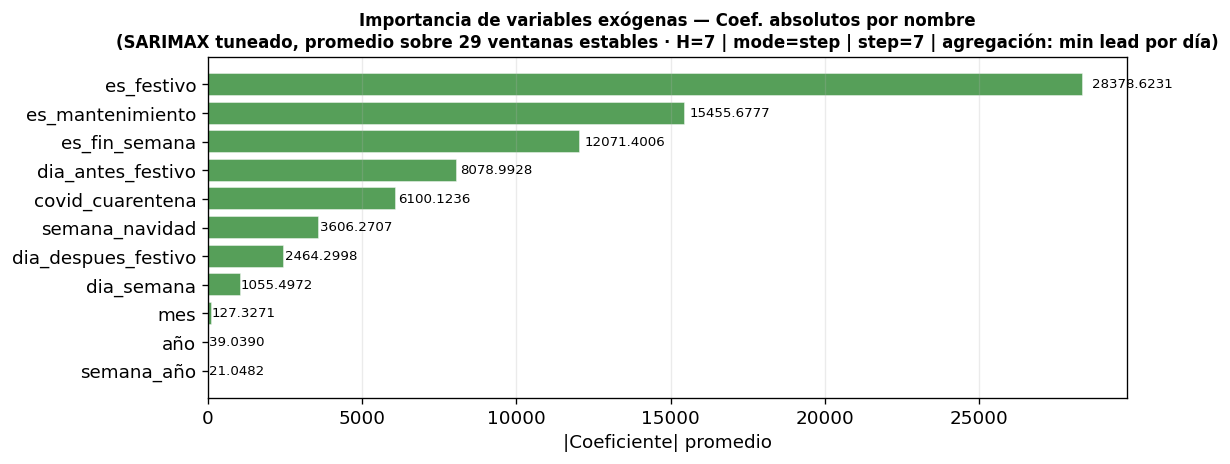

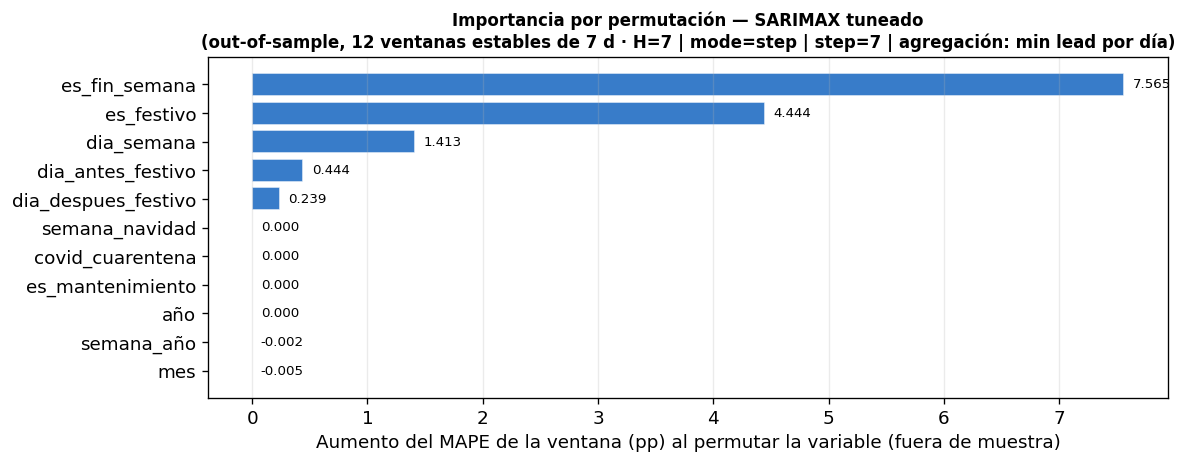

── Coeficientes vs Permutación (top-15 por permutación) ──
                     Coef. abs. (por nombre)  Permutación (ΔMAPE pp)
es_fin_semana                     12071.4006                  7.5646
es_festivo                        28378.6231                  4.4439
dia_semana                         1055.4972                  1.4132
dia_antes_festivo                  8078.9928                  0.4440
dia_despues_festivo                2464.2998                  0.2394
covid_cuarentena                   6100.1236                  0.0000
año                                  39.0390                  0.0000
es_mantenimiento                  15455.6777                  0.0000
semana_navidad                     3606.2707                  0.0000
semana_año                           21.0482                 -0.0022
mes                                 127.3271                 -0.0046

→ Guardado: feature_importance_perm_sarimax_H7_step7.csv


In [ ]:
# ── A · Coeficientes exógenos extraídos por NOMBRE (no por posición) ─────────
coef_rows = []
for t in STABLE_TEST_ORIGINS['origin']:
    coefs = per_origin[t]['tuned']['coefs']
    if coefs:
        coef_rows.append(pd.Series(coefs))

if coef_rows:
    avg_coef = pd.concat(coef_rows, axis=1).mean(axis=1).abs().nlargest(min(20, len(EXOG_COLS))).sort_values()
    fig, ax = plt.subplots(figsize=(10, max(4, len(avg_coef)*0.35)))
    bars = ax.barh(avg_coef.index, avg_coef.values, color=SARIMAX_COLOR, alpha=0.85, edgecolor='white')
    for bar, v in zip(bars, avg_coef.values):
        ax.text(v*1.01, bar.get_y()+bar.get_height()/2, f'{v:.4f}', va='center', fontsize=8)
    ax.set_title('Importancia de variables exógenas — Coef. absolutos por nombre\n'
                 f'(SARIMAX tuneado, promedio sobre {len(coef_rows)} ventanas estables · {run_subtitle()})',
                 fontweight='bold', fontsize=10)
    ax.set_xlabel('|Coeficiente| promedio')
    ax.grid(True, axis='x', alpha=0.25)
    plt.tight_layout()
    plt.savefig(f'feature_importance_coef_sarimax_{RUN_TAG}.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    avg_coef = pd.Series(dtype=float)
    print("⚠ No se pudieron extraer coeficientes exógenos por nombre en ninguna ventana estable.")

# ── B · Importancia por permutación (out-of-sample, sin reentrenar) ──────────
def exog_permutation_importance(model, X_te, y_te, exog_cols, base_mape, n_repeats=10, seed=SEED):
    """Para cada variable, baraja su columna en X_te y mide cuánto empeora el MAPE al volver
    a predecir con el modelo YA ajustado (no reentrena)."""
    rng_local = np.random.default_rng(seed)
    deltas = {}
    for col in exog_cols:
        increases = []
        for _ in range(n_repeats):
            X_perm = X_te.copy()
            X_perm[col] = rng_local.permutation(X_perm[col].to_numpy())
            try:
                preds_perm = np.asarray(model.predict(n_periods=len(y_te), X=X_perm), dtype=float)
                if np.all(np.isnan(preds_perm)):
                    continue
                mape_perm = compute_metrics(y_te, preds_perm)['MAPE (%)']
                increases.append(mape_perm - base_mape)
            except Exception:
                continue
        deltas[col] = float(np.mean(increases)) if increases else np.nan
    return deltas

perm_series = []
for t in PERM_ORIGINS:
    r = per_origin[t]['tuned']
    model = r['model']
    if model is None:
        continue
    base_mape = r['metrics']['MAPE (%)']
    if np.isnan(base_mape):
        continue
    deltas = exog_permutation_importance(model, r['X_test'], r['real'], EXOG_COLS, base_mape,
                                         n_repeats=10, seed=SEED)
    perm_series.append(pd.Series(deltas))

if perm_series:
    perm_imp = pd.concat(perm_series, axis=1).mean(axis=1)   # ΔMAPE (pp) promedio por variable
    perm_top = perm_imp.dropna().nlargest(min(20, len(EXOG_COLS))).sort_values()

    fig, ax = plt.subplots(figsize=(10, max(4, len(perm_top)*0.35)))
    bars = ax.barh(perm_top.index, perm_top.values, color='#1565C0', alpha=0.85, edgecolor='white')
    _xmax = max(perm_top.values.max(), 1e-9)
    for bar, v in zip(bars, perm_top.values):
        ax.text(v + _xmax*0.01, bar.get_y()+bar.get_height()/2, f'{v:.3f}', va='center', fontsize=8)
    ax.set_title('Importancia por permutación — SARIMAX tuneado\n'
                 f'(out-of-sample, {len(perm_series)} ventanas estables de {H} d · {run_subtitle()})',
                 fontweight='bold', fontsize=10)
    ax.set_xlabel('Aumento del MAPE de la ventana (pp) al permutar la variable (fuera de muestra)')
    ax.grid(True, axis='x', alpha=0.25)
    plt.tight_layout()
    plt.savefig(f'feature_importance_perm_sarimax_{RUN_TAG}.png', dpi=150, bbox_inches='tight')
    plt.show()

    if not avg_coef.empty:
        cmp_imp = (pd.DataFrame({'Coef. abs. (por nombre)': avg_coef.reindex(perm_imp.index),
                                 'Permutación (ΔMAPE pp)': perm_imp})
                     .sort_values('Permutación (ΔMAPE pp)', ascending=False).head(15))
        print("── Coeficientes vs Permutación (top-15 por permutación) ──")
        print(cmp_imp.round(4).to_string())

    perm_imp.sort_values(ascending=False).to_csv(f'feature_importance_perm_sarimax_{RUN_TAG}.csv', header=['perm_dMAPE_pp'])
    print(f"\n→ Guardado: feature_importance_perm_sarimax_{RUN_TAG}.csv")
else:
    perm_imp = pd.Series(dtype=float)
    print("⚠ No se pudo calcular importancia por permutación en ninguna ventana estable.")

## 16. APE promedio por horizonte (lead 1…H) — Default vs Tuneado (ventanas estables)

Mismo eje que la Sección 11: **lead time 1…H** (no el día del mes). Se promedia el APE sobre las ventanas estables.
La leyenda incluye la **pendiente** (pp de APE por día de horizonte) como resumen de cuánto degrada cada variante.

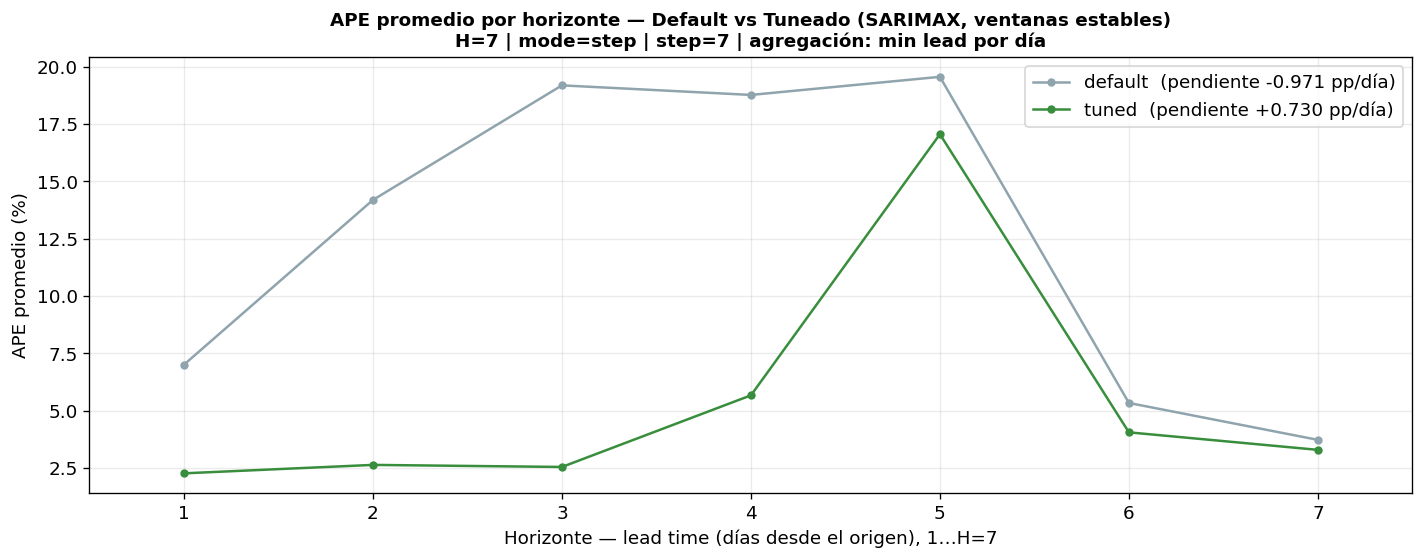

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4.8))
for variant in VARIANTS:
    g = lc[lc['variant'] == variant].dropna(subset=['ape'])
    slope = np.polyfit(g['lead'], g['ape'], 1)[0] if len(g) > 2 else np.nan
    ax.plot(g['lead'], g['ape'], '-o', ms=4, lw=1.5, color=VCOLORS[variant],
            label=f"{variant}  (pendiente {slope:+.3f} pp/día)")
ax.set_xlabel(f'Horizonte — lead time (días desde el origen), 1…H={H}'); ax.set_ylabel('APE promedio (%)')
ax.set_xlim(0.5, H + 0.5)
ax.set_title(f'APE promedio por horizonte — Default vs Tuneado (SARIMAX, ventanas estables)\n{run_subtitle()}',
             fontweight='bold', fontsize=11)
ax.legend(); ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(f'ape_horizonte_sarimax_{RUN_TAG}.png', dpi=150, bbox_inches='tight')
plt.show()

## 17. Comparación directa por mes — MAPE default vs tuned (con mejora)

In [ ]:
rows = []
for mes in TEST_MONTHS:
    md_ = results[mes]['default']['metrics']['MAPE (%)']
    mt_ = results[mes]['tuned']['metrics']['MAPE (%)']
    rows.append({'Mes': mes, 'Atípico': is_atyp(mes),
                 'MAPE default': round(md_, 2) if not np.isnan(md_) else None,
                 'MAPE tuned': round(mt_, 2) if not np.isnan(mt_) else None,
                 'Δ': round(mt_ - md_, 2) if not (np.isnan(md_) or np.isnan(mt_)) else None,
                 '% mejora': round((md_ - mt_)/md_*100, 1) if (md_ and not np.isnan(md_) and not np.isnan(mt_)) else None})
cmp_df = pd.DataFrame(rows)
print(f"══ MAPE por mes: default vs tuned  ({run_subtitle()}) ══")
print(cmp_df.to_string(index=False))

md_avg = np.nanmean([results[m]['default']['metrics']['MAPE (%)'] for m in STABLE_MONTHS])
mt_avg = np.nanmean([results[m]['tuned']['metrics']['MAPE (%)'] for m in STABLE_MONTHS])
print(f"\n(meses estables)  MAPE default = {md_avg:.2f}%   |   tuned = {mt_avg:.2f}%   "
      f"|   mejora = {(md_avg-mt_avg)/md_avg*100:+.1f}%")

══ MAPE por mes: default vs tuned  (H=7 | mode=step | step=7 | agregación: min lead por día) ══
    Mes  Atípico  MAPE default  MAPE tuned     Δ  % mejora
2025-01    False         12.51        7.16 -5.34      42.7
2025-02    False         12.77        5.10 -7.67      60.1
2025-03     True         14.68        9.06 -5.62      38.3
2025-04    False         13.94        5.82 -8.12      58.2
2025-05     True         13.51        5.08 -8.43      62.4
2025-06    False         10.55        4.90 -5.65      53.6
2025-07    False         12.66        5.63 -7.03      55.5
2025-08    False         13.63        4.92 -8.71      63.9
2025-09    False         11.35        4.23 -7.12      62.7
2025-10     True         25.24       29.11  3.87     -15.3
2025-11     True         14.00        8.47 -5.53      39.5
2025-12     True         13.01        7.85 -5.16      39.6

(meses estables)  MAPE default = 12.49%   |   tuned = 5.39%   |   mejora = +56.8%


## 18. Intervalos — confianza del MAPE mensual y bandas de pronóstico

**A. Intervalo de confianza del MAPE mensual** (default y tuneado, con y sin atípicos): el MAPE de cada mes calendario
(serie agregada *min lead por día*) se trata como una muestra. **IC del MAPE medio** (incertidumbre del promedio) e
**IP de un mes nuevo** (dónde caerá el MAPE de un mes, más ancho). Mismas fórmulas t-Student.

**B. Banda diaria alrededor del pronóstico tuneado** — **conformal split condicionado por día de la semana** (misma
función portable `weekday_conformal_bands`). Se calibra con residuos **fuera de muestra de las ventanas de CV del modo
elegido** (mismos orígenes `CV_ORIGINS`, mismo `H`) **agregados con la misma política *min lead por día*** que la serie
que se grafica, para que la calibración sea coherente con lo que se muestra. Se reporta la **cobertura empírica** en meses estables.

══════════════════════════════════════════════════════════════════════
  INTERVALOS DEL MAPE MENSUAL  (nivel 90%)  —  H=7 | mode=step | step=7 | agregación: min lead por día
══════════════════════════════════════════════════════════════════════
Variante    Escenario  n  MAPE medio  MAPE mediana  std   min   max    IC90% media   IP90% un mes
 default Con atípicos 12       13.99         13.26 3.72 10.55 25.24 [12.06, 15.92]  [7.03, 20.95]
 default Sin atípicos  7       12.49         12.66 1.19 10.55 13.94 [11.61, 13.36] [10.01, 14.97]
   tuned Con atípicos 12        8.11          5.72 6.80  4.23 29.11  [4.59, 11.63]  [0.00, 20.81]
   tuned Sin atípicos  7        5.39          5.10 0.94  4.23  7.16   [4.71, 6.08]   [3.45, 7.34]

→ Guardado: intervalos_mape_sarimax_H7_step7.csv


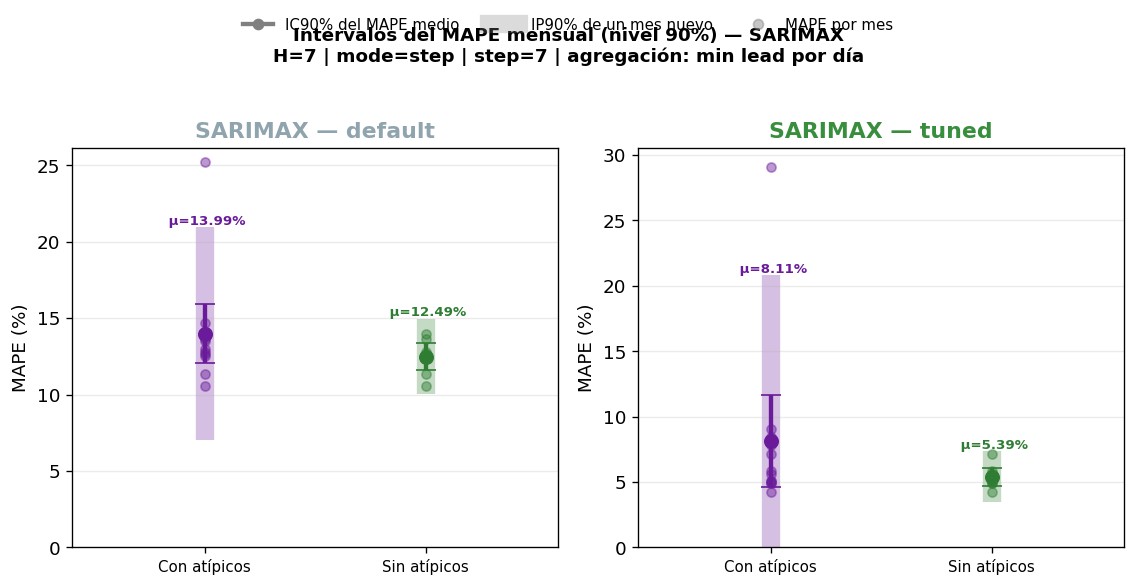

Recolectando residuos out-of-sample de las ventanas de CV (SARIMAX tuneado)…


CV para calibración:   0%|          | 0/12 [00:00<?, ?it/s]

  n calibración = 84  (12 ventanas de 7 d, agregación min lead por día, atípicas excluidas)


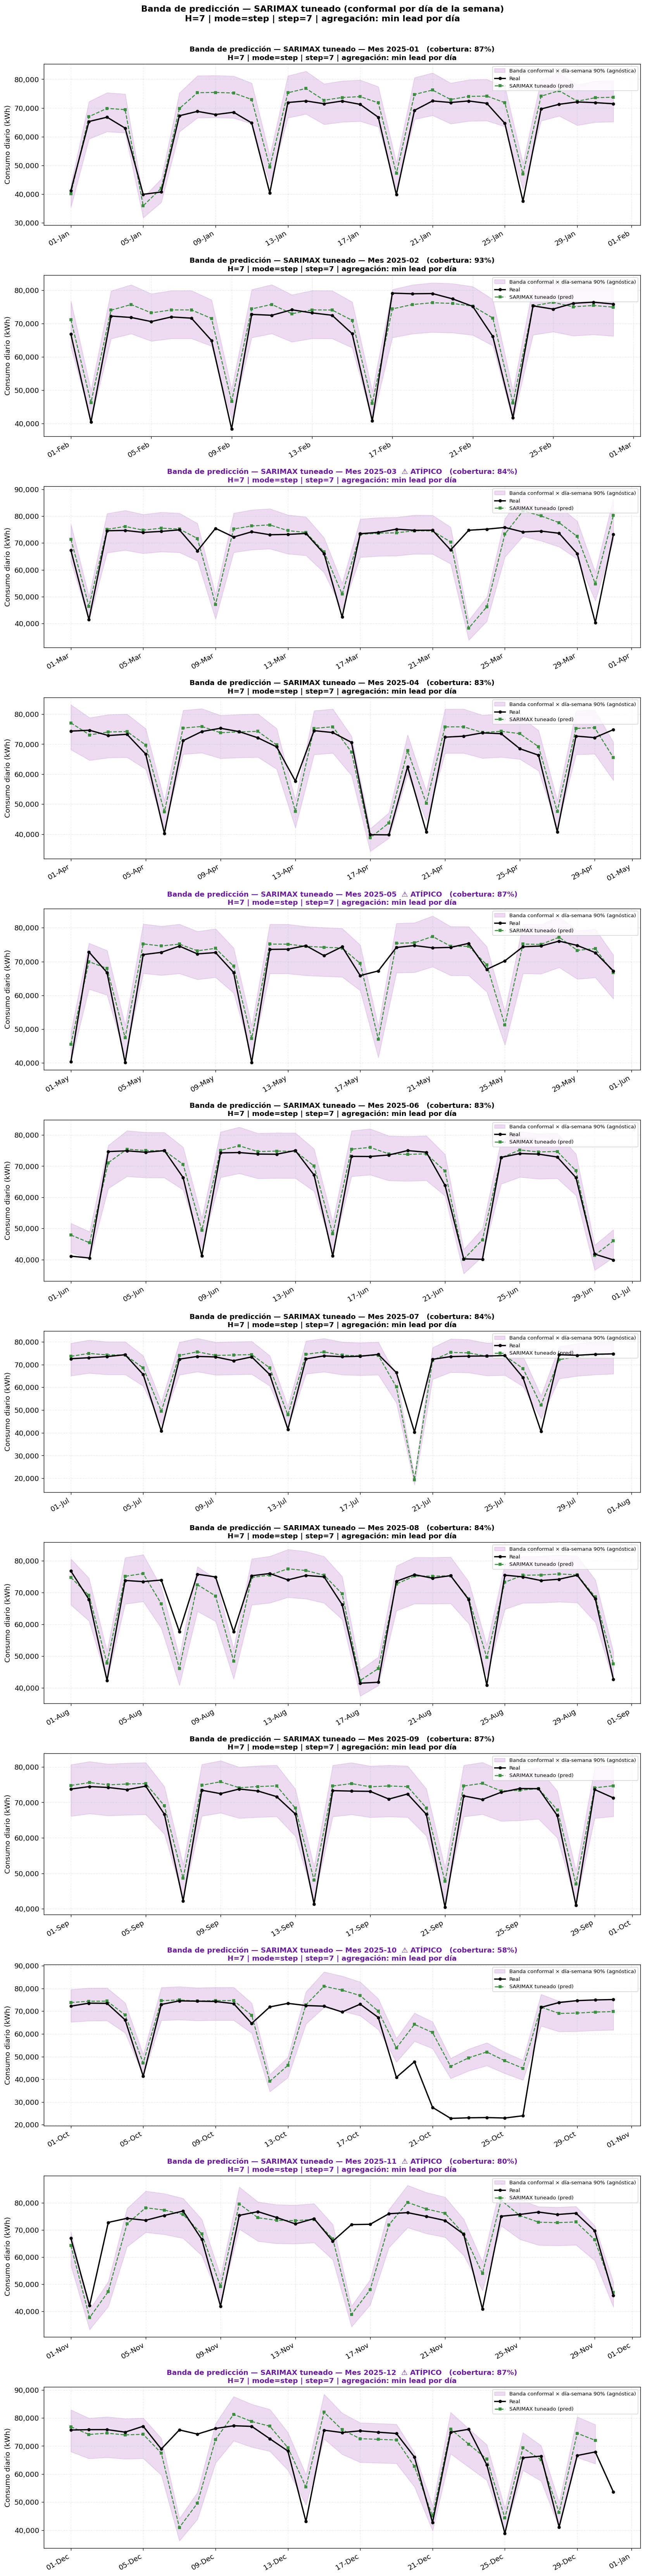


══ Cobertura empírica 90% (meses estables) ══
  Conformal × día-semana : cobertura media = 85.9%  (objetivo 90%)


In [ ]:
# ── A · Intervalo de confianza / predicción del MAPE mensual ─────────────────
Z   = CI_LEVEL
pct = int(round(Z * 100))

def _mape_por_mes(variant, meses):
    return np.array([results[m][variant]['metrics']['MAPE (%)'] for m in meses], dtype=float)

def _intervalos_mape(vals, level=Z):
    vals = vals[~np.isnan(vals)]
    n = len(vals)
    mean = float(np.mean(vals)) if n else np.nan
    med = float(np.median(vals)) if n else np.nan
    sd   = float(np.std(vals, ddof=1)) if n > 1 else 0.0
    out = {'n': n, 'media': mean, 'mediana': med, 'std': sd,
           'min': float(np.min(vals)) if n else np.nan, 'max': float(np.max(vals)) if n else np.nan,
           'ic_media': (mean, mean), 'ip_mes': (mean, mean), 'vals': vals}
    if n > 1:
        t = float(stats.t.ppf(0.5 + level/2, df=n-1)); se = sd/np.sqrt(n)
        out['ic_media'] = (mean - t*se,                  mean + t*se)
        out['ip_mes']   = (mean - t*sd*np.sqrt(1 + 1/n), mean + t*sd*np.sqrt(1 + 1/n))
    return out

_escenarios = {'Con atípicos': TEST_MONTHS, 'Sin atípicos': STABLE_MONTHS}
_store, _rows = {}, []
for variant in VARIANTS:
    _store[variant] = {}
    for esc, meses in _escenarios.items():
        vals = _mape_por_mes(variant, meses); s = _intervalos_mape(vals)
        _store[variant][esc] = s
        ic = (max(0.0, s['ic_media'][0]), s['ic_media'][1])
        ip = (max(0.0, s['ip_mes'][0]),   s['ip_mes'][1])
        _rows.append({'Variante': variant, 'Escenario': esc, 'n': s['n'],
                      'MAPE medio': round(s['media'], 2), 'MAPE mediana': round(s['mediana'], 2),
                      'std': round(s['std'], 2), 'min': round(s['min'], 2), 'max': round(s['max'], 2),
                      f'IC{pct}% media': f"[{ic[0]:.2f}, {ic[1]:.2f}]",
                      f'IP{pct}% un mes': f"[{ip[0]:.2f}, {ip[1]:.2f}]"})

ic_mape_df = pd.DataFrame(_rows)
print(f"{'═'*70}\n  INTERVALOS DEL MAPE MENSUAL  (nivel {pct}%)  —  {run_subtitle()}\n{'═'*70}")
print(ic_mape_df.to_string(index=False))
ic_mape_df.to_csv(f'intervalos_mape_sarimax_{RUN_TAG}.csv', index=False)
print(f"\n→ Guardado: intervalos_mape_sarimax_{RUN_TAG}.csv")

# Gráfica: IC del MAPE medio (barra fuerte) + IP de un mes (barra ancha clara), por variante
fig, axes = plt.subplots(1, len(VARIANTS), figsize=(4.8*len(VARIANTS), 4.6), sharex=False)
if len(VARIANTS) == 1: axes = [axes]
offsets = {'Con atípicos': 0.0, 'Sin atípicos': 1.0}
ecolor  = {'Con atípicos': COLOR_ATYPICAL, 'Sin atípicos': '#2E7D32'}
for ax, variant in zip(axes, VARIANTS):
    for esc in _escenarios:
        s = _store[variant][esc]; x = offsets[esc]; m = s['media']
        if np.isnan(m):
            continue
        ic = (max(0.0, s['ic_media'][0]), s['ic_media'][1])
        ip = (max(0.0, s['ip_mes'][0]),   s['ip_mes'][1])
        ax.scatter(np.full(len(s['vals']), x), s['vals'], color=ecolor[esc], alpha=0.45, s=30, zorder=2)
        ax.errorbar(x, m, yerr=[[m-ip[0]], [ip[1]-m]], fmt='none', ecolor=ecolor[esc],
                    alpha=0.28, elinewidth=11, zorder=1)
        ax.errorbar(x, m, yerr=[[m-ic[0]], [ic[1]-m]], fmt='o', color=ecolor[esc],
                    ecolor=ecolor[esc], elinewidth=2.6, capsize=6, ms=8, zorder=3)
        ax.text(x, ip[1], f' μ={m:.2f}%', va='bottom', ha='center',
                fontsize=8, color=ecolor[esc], fontweight='bold')
    ax.set_xticks(list(offsets.values())); ax.set_xticklabels(list(offsets.keys()), fontsize=9)
    ax.set_xlim(-0.6, 1.6); ax.set_ylim(bottom=0)
    ax.set_title(f'SARIMAX — {variant}', fontweight='bold', color=VCOLORS[variant])
    ax.set_ylabel('MAPE (%)'); ax.grid(True, axis='y', alpha=0.25)
handles = [Line2D([0],[0], color='gray', lw=2.6, marker='o', label=f'IC{pct}% del MAPE medio'),
           Line2D([0],[0], color='gray', lw=11, alpha=0.28, label=f'IP{pct}% de un mes nuevo'),
           Line2D([0],[0], color='gray', lw=0, marker='o', alpha=0.45, label='MAPE por mes')]
fig.legend(handles=handles, loc='upper center', ncol=3, fontsize=9,
           bbox_to_anchor=(0.5, 1.07), frameon=False)
plt.suptitle(f'Intervalos del MAPE mensual (nivel {pct}%) — SARIMAX\n{run_subtitle()}',
             fontweight='bold', y=1.03, fontsize=11)
plt.tight_layout()
plt.savefig(f'intervalos_mape_sarimax_{RUN_TAG}.png', dpi=150, bbox_inches='tight')
plt.show()

# ── B · Banda conformal condicionada por día de la semana (SARIMAX tuneado) ──
PI = CI_LEVEL

def weekday_conformal_bands(cal_dates, cal_real, cal_pred,
                            target_dates, target_pred,
                            level=PI, mode='relative', min_group=15):
    a = 1 - level; ql, qh = a / 2, 1 - a / 2
    cal_real = np.asarray(cal_real, float); cal_pred = np.asarray(cal_pred, float)
    cal_wd = pd.DatetimeIndex(cal_dates).weekday.to_numpy()
    if mode == 'relative':
        ok = (cal_pred != 0) & ~np.isnan(cal_pred) & ~np.isnan(cal_real)
        resid  = (cal_real[ok] - cal_pred[ok]) / cal_pred[ok]
        cal_wd = cal_wd[ok]
    else:  # 'absolute'
        ok = ~np.isnan(cal_pred) & ~np.isnan(cal_real)
        resid = (cal_real - cal_pred)[ok]; cal_wd = cal_wd[ok]
    g_lo, g_hi = np.quantile(resid, ql), np.quantile(resid, qh)      # respaldo global
    lo_wd, hi_wd = {}, {}
    for w in range(7):
        r = resid[cal_wd == w]
        if len(r) >= min_group:
            lo_wd[w], hi_wd[w] = np.quantile(r, ql), np.quantile(r, qh)
        else:
            lo_wd[w], hi_wd[w] = g_lo, g_hi                          # weekday con pocos datos -> global
    tp  = np.asarray(target_pred, float)
    twd = pd.DatetimeIndex(target_dates).weekday.to_numpy()
    lo  = np.array([lo_wd[w] for w in twd]); hi = np.array([hi_wd[w] for w in twd])
    if mode == 'relative':
        return tp * (1 + lo), tp * (1 + hi)
    return tp + lo, tp + hi

# Calibración: residuos OOS del SARIMAX tuneado sobre las ventanas de CV (mismo H / modo),
# agregados con la MISMA política min-lead que la serie mostrada.
CAL_MODE = 'relative'   # 'relative' (multiplicativo, se adapta al nivel) | 'absolute' (aditivo)
print("Recolectando residuos out-of-sample de las ventanas de CV (SARIMAX tuneado)…")
cv_long, _ = evaluate_origins(CV_ORIGINS, {'tuned': best_params_sarimax}, desc='CV para calibración')
cv_agg = aggregate_min_lead(cv_long).dropna(subset=['pred', 'real'])
cal_D = pd.DatetimeIndex(cv_agg['Fecha']); cal_R = cv_agg['real'].to_numpy(float); cal_P = cv_agg['pred'].to_numpy(float)
print(f"  n calibración = {len(cal_R)}  ({len(CV_ORIGINS)} ventanas de {H} d, agregación {AGG_POLICY}, atípicas excluidas)")

_band_cache = {}
def get_band(mes):
    if mes not in _band_cache:
        rr = results[mes]['tuned']
        _band_cache[mes] = weekday_conformal_bands(cal_D, cal_R, cal_P, rr['dates'], rr['preds'],
                                                   level=PI, mode=CAL_MODE)
    return _band_cache[mes]

def _cobertura(mes):
    rr = results[mes]['tuned']; lo_w, hi_w = get_band(mes)
    v = ~np.isnan(rr['preds']) & ~np.isnan(rr['real'])
    return float(np.mean((rr['real'][v] >= lo_w[v]) & (rr['real'][v] <= hi_w[v]))) * 100 if v.any() else np.nan

# ── Gráfica: banda conformal por mes ──────────────────────────────────────────
n = len(PLOT_MONTHS)
fig, axes = plt.subplots(n, 1, figsize=(14, 4.6*n), sharex=False)
if n == 1: axes = [axes]
for ax, mes in zip(axes, PLOT_MONTHS):
    rr = results[mes]['tuned']
    dates, real, pred = rr['dates'], rr['real'], rr['preds']
    lo_w, hi_w = get_band(mes)
    ax.fill_between(dates, lo_w, hi_w, color='#8E24AA', alpha=0.16,
                    label=f'Banda conformal × día-semana {int(PI*100)}% (agnóstica)')
    ax.plot(dates, real, 'k-o', lw=2, ms=4, label='Real', zorder=6)
    ax.plot(dates, pred, '--s', ms=3.5, lw=1.5, color=SARIMAX_COLOR, label='SARIMAX tuneado (pred)', zorder=5)
    cov_w = _cobertura(mes)
    tag = '  ⚠ ATÍPICO' if is_atyp(mes) else ''
    cov_txt = f"{cov_w:.0f}%" if not np.isnan(cov_w) else "n/d"
    ax.set_title(f'Banda de predicción — SARIMAX tuneado — Mes {mes}{tag}   (cobertura: {cov_txt})\n{run_subtitle()}',
                 fontweight='bold', fontsize=11, color=(COLOR_ATYPICAL if is_atyp(mes) else 'black'))
    ax.set_ylabel('Consumo diario (kWh)'); ax.legend(loc='upper right', fontsize=8)
    ax.grid(True, alpha=0.25, ls='--')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%b'))
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
plt.suptitle(f'Banda de predicción — SARIMAX tuneado (conformal por día de la semana)\n{run_subtitle()}',
             fontweight='bold', y=1.003)
plt.tight_layout()
plt.savefig(f'bandas_prediccion_sarimax_{RUN_TAG}.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Cobertura empírica sobre meses estables (objetivo = nivel nominal) ────────
print(f"\n══ Cobertura empírica {int(PI*100)}% (meses estables) ══")
cov_w_all = [c for c in (_cobertura(m) for m in STABLE_MONTHS) if not np.isnan(c)]
if cov_w_all:
    print(f"  Conformal × día-semana : cobertura media = {np.mean(cov_w_all):.1f}%  (objetivo {int(PI*100)}%)")
else:
    print("  (sin meses estables con cobertura)")

## 19. Resumen sobre meses estables y exportación

Se exportan (con sufijo `RUN_TAG`, p. ej. `H60_month_start`, para no pisar corridas de otros regímenes):

* `predicciones_sarimax_<tag>.csv` — **por fila de predicción**: `origen, lead, Fecha, Mes, variante, real, pred…` + `H, ORIGIN_MODE, STEP`.
* `predicciones_mensuales_sarimax_<tag>.csv` — serie mensual agregada (*min lead por día*) con el `origen`/`lead` elegido por día.
* `metricas_sarimax_<tag>.csv` (por mes calendario) y `metricas_por_origen_sarimax_<tag>.csv` (por ventana).
* `error_por_lead_sarimax_<tag>.csv` — degradación del error por lead 1…H.
* `tuning_…`, `resumen_meses_estables_…`, `best_params_sarimax_<tag>.json` (con metadatos de `H`, modo, step y política).

In [ ]:
# ── Resumen (solo meses estables) ────────────────────────────────────────────
summary_rows = []
for variant in VARIANTS:
    a = _avg_metrics(variant, STABLE_MONTHS)
    summary_rows.append({'Variante': variant, 'MAE': round(a['MAE'], 0), 'RMSE': round(a['RMSE'], 0),
                         'MAPE (%)': round(a['MAPE (%)'], 2), 'R²': round(a['R²'], 4)})
summary_stable = pd.DataFrame(summary_rows).set_index('Variante')
d_mape = summary_stable.loc['default', 'MAPE (%)']; t_mape = summary_stable.loc['tuned', 'MAPE (%)']
print(f"══ RESUMEN — MESES ESTABLES (SARIMAX) — {run_subtitle()} ══")
print(summary_stable.to_string())
print(f"\n→ MAPE default = {d_mape:.2f}%  →  tuneado = {t_mape:.2f}%  "
      f"(mejora {(d_mape-t_mape)/d_mape*100:+.1f}%)")

# ── Predicciones POR ORIGEN (una fila por origen × lead × variante) ──────────
meta = {'H': H, 'ORIGIN_MODE': ORIGIN_MODE, 'STEP': (STEP if ORIGIN_MODE == 'step' else None)}
ex = preds_long.copy()
ex['AbsError'] = (ex['real'] - ex['pred']).abs()
ex['APE (%)']  = np.where(ex['real'] != 0, ex['AbsError'] / ex['real'].replace(0, np.nan) * 100, np.nan)
ex['Atipico_mes'] = ex['Mes'].isin(ATYPICAL_MONTHS)
ex = ex.rename(columns={'origin': 'Origen', 'variant': 'Variante', 'lead': 'Lead', 'real': 'Real',
                        'pred': 'Prediccion', 'window_atyp': 'Atipico_ventana'})
ex['Origen'] = ex['Origen'].dt.date; ex['Fecha'] = ex['Fecha'].dt.date
for k, v in meta.items(): ex[k] = v
ex = ex[['Origen', 'Lead', 'Fecha', 'Mes', 'Variante', 'Real', 'Prediccion', 'AbsError', 'APE (%)',
         'Atipico_ventana', 'Atipico_mes', 'H', 'ORIGIN_MODE', 'STEP']].round({'Prediccion': 2, 'AbsError': 2, 'APE (%)': 4})
ex.to_csv(f'predicciones_sarimax_{RUN_TAG}.csv', index=False)

# ── Serie MENSUAL agregada (min lead por día) ────────────────────────────────
mag = aggregate_min_lead(preds_long).copy()
mag['AbsError'] = (mag['real'] - mag['pred']).abs()
mag['APE (%)']  = np.where(mag['real'] != 0, mag['AbsError'] / mag['real'].replace(0, np.nan) * 100, np.nan)
mag['Atipico_mes'] = mag['Mes'].isin(ATYPICAL_MONTHS)
mag['Agregacion'] = AGG_POLICY
mag = mag.rename(columns={'origin': 'Origen_usado', 'variant': 'Variante', 'lead': 'Lead', 'real': 'Real', 'pred': 'Prediccion'})
mag['Origen_usado'] = mag['Origen_usado'].dt.date; mag['Fecha'] = mag['Fecha'].dt.date
for k, v in meta.items(): mag[k] = v
mag = mag[['Fecha', 'Mes', 'Atipico_mes', 'Variante', 'Origen_usado', 'Lead', 'Real', 'Prediccion',
           'AbsError', 'APE (%)', 'Agregacion', 'H', 'ORIGIN_MODE', 'STEP']].round({'Prediccion': 2, 'AbsError': 2, 'APE (%)': 4})
mag.to_csv(f'predicciones_mensuales_sarimax_{RUN_TAG}.csv', index=False)

# ── Métricas, degradación, tuning y params ───────────────────────────────────
metrics_df.assign(H=H, ORIGIN_MODE=ORIGIN_MODE, STEP=meta['STEP'], Agregacion=AGG_POLICY)\
          .to_csv(f'metricas_sarimax_{RUN_TAG}.csv', index=False)
origin_metrics_df.assign(H=H, ORIGIN_MODE=ORIGIN_MODE, STEP=meta['STEP'])\
                 .to_csv(f'metricas_por_origen_sarimax_{RUN_TAG}.csv', index=False)
lc.rename(columns={'variant': 'Variante', 'lead': 'Lead', 'mae': 'MAE_kWh', 'ape': 'APE_pct', 'n': 'n_ventanas'})\
  .assign(H=H, ORIGIN_MODE=ORIGIN_MODE, STEP=meta['STEP'])\
  .to_csv(f'error_por_lead_sarimax_{RUN_TAG}.csv', index=False)
tuning_df.to_csv(f'tuning_sarimax_{RUN_TAG}.csv', index=False)
summary_stable.to_csv(f'resumen_meses_estables_sarimax_{RUN_TAG}.csv')
with open(f'best_params_sarimax_{RUN_TAG}.json', 'w') as f:
    json.dump({'metadata': {**meta, 'agregacion_mensual': AGG_POLICY,
                            'min_window_test': MIN_WINDOW_EFF, 'atypical_overlap_thr': ATYPICAL_OVERLAP_THR,
                            'n_cv_origins': int(len(CV_ORIGINS)), 'n_test_origins': int(len(test_origins)),
                            'n_test_origins_estables': int(len(STABLE_TEST_ORIGINS)),
                            'train_start': TRAIN_START, 'test_start': TEST_START,
                            'atypical_months': ATYPICAL_MONTHS, 'seasonal_m': SEASONAL_M, 'run_tuning': RUN_TUNING},
               'default': DEFAULT_SARIMAX, 'tuned': best_params_sarimax,
               'best_known': BEST_KNOWN_SARIMAX,
               'cv_known': known_stats, 'cv_tuned': best_stats}, f, indent=2, default=str)

print(f"\nArchivos exportados (tag = {RUN_TAG}):")
for name in ['predicciones_sarimax', 'predicciones_mensuales_sarimax', 'metricas_sarimax',
             'metricas_por_origen_sarimax', 'error_por_lead_sarimax', 'tuning_sarimax',
             'intervalos_mape_sarimax', 'feature_importance_perm_sarimax', 'resumen_meses_estables_sarimax']:
    print(f"  {name}_{RUN_TAG}.csv")
print(f"  best_params_sarimax_{RUN_TAG}.json   — default / tuned / best-known + scores CV + metadatos (H, modo, step, agregación)")

══ RESUMEN — MESES ESTABLES (SARIMAX) — H=7 | mode=step | step=7 | agregación: min lead por día ══
             MAE    RMSE  MAPE (%)      R²
Variante                                  
default   7865.0  9327.0     12.49  0.3766
tuned     2993.0  4079.0      5.39  0.8779

→ MAPE default = 12.49%  →  tuneado = 5.39%  (mejora +56.8%)

Archivos exportados (tag = H7_step7):
  predicciones_sarimax_H7_step7.csv
  predicciones_mensuales_sarimax_H7_step7.csv
  metricas_sarimax_H7_step7.csv
  metricas_por_origen_sarimax_H7_step7.csv
  error_por_lead_sarimax_H7_step7.csv
  tuning_sarimax_H7_step7.csv
  intervalos_mape_sarimax_H7_step7.csv
  feature_importance_perm_sarimax_H7_step7.csv
  resumen_meses_estables_sarimax_H7_step7.csv
  best_params_sarimax_H7_step7.json   — default / tuned / best-known + scores CV + metadatos (H, modo, step, agregación)


## 20. (Opcional) Comparación A / B / C con parámetros ya fijados

Con `RUN_EXPERIMENTS = True` se evalúa cada combinación de `EXPERIMENTOS` (`H`, `ORIGIN_MODE`, `STEP`) sobre **el mismo
periodo de test**, reutilizando los **hiperparámetros ya tuneados** arriba (no se vuelve a correr Optuna). Se compara:
MAPE mensual estable (agregación *min lead por día*), MAPE medio por ventana estable, APE en lead 1 y en lead H, y costo
(nº de fits y tiempo). **El modo A (`STEP=1`) ajusta un SARIMAX por día de test**: puede tardar bastante.

In [ ]:
def run_experiment(exp, variants=EXP_VARIANTS):
    h, mode, step = int(exp['H']), exp['ORIGIN_MODE'], exp.get('STEP')
    mw = min(h, max(20, h // 2))
    orig = generate_origins(df, test_start, df.index.max(), h, mode, step if step else 1, min_len=mw)
    pbv = {v: (DEFAULT_SARIMAX if v == 'default' else best_params_sarimax) for v in variants}
    t_ini = time.time()
    pl, _ = evaluate_origins(orig, pbv, desc=f"{exp['name']}")
    mon = build_monthly(pl, TEST_MONTHS, list(variants))
    lcx = lead_curve(pl, h, only_stable=True)
    out = []
    for v in variants:
        mm = [mon[m][v]['metrics']['MAPE (%)'] for m in STABLE_MONTHS]
        mw_ = []
        for t_, g in pl[(pl['variant'] == v) & (~pl['window_atyp'])].groupby('origin'):
            g = g.dropna(subset=['pred', 'real'])
            if len(g): mw_.append(compute_metrics(g['real'], g['pred'])['MAPE (%)'])
        g = lcx[lcx['variant'] == v].set_index('lead')
        out.append({'Experimento': exp['name'], 'Variante': v, 'H': h, 'ORIGIN_MODE': mode,
                    'STEP': step if mode == 'step' else None, 'n_origenes': len(orig),
                    'n_fits': len(orig) * len(variants), 'tiempo_min': round((time.time() - t_ini) / 60, 2),
                    'MAPE mensual estable (%)': round(float(np.nanmean(mm)), 3) if np.any(~np.isnan(mm)) else np.nan,
                    'MAPE ventana estable (%)': round(float(np.mean(mw_)), 3) if mw_ else np.nan,
                    'APE lead 1 (%)': round(float(g['ape'].get(1, np.nan)), 3),
                    'APE lead H (%)': round(float(g['ape'].get(h, np.nan)), 3)})
    return out, lcx

if RUN_EXPERIMENTS:
    exp_rows, exp_curves = [], {}
    for exp in EXPERIMENTOS:
        rows_, lcx = run_experiment(exp)
        exp_rows.extend(rows_)
        exp_curves[exp['name']] = (exp, lcx)
    exp_df = pd.DataFrame(exp_rows)
    print("══ Comparación de regímenes de origen (parámetros tuned fijos) ══")
    print(exp_df.to_string(index=False))
    exp_df.to_csv(f'comparacion_experimentos_sarimax_H{H}.csv', index=False)

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
    palette = plt.cm.tab10.colors
    for k, (name, (exp, lcx)) in enumerate(exp_curves.items()):
        for v in EXP_VARIANTS:
            g = lcx[lcx['variant'] == v]
            for ax, col in zip(axes, ['mae', 'ape']):
                ax.plot(g['lead'], g[col], '-', lw=1.8, color=palette[k % 10],
                        ls='-' if v == 'tuned' else '--', label=f"{name} ({v})")
    axes[0].set_ylabel('|Error| medio (kWh)'); axes[1].set_ylabel('APE medio (%)')
    for ax in axes:
        ax.set_xlabel('Lead time (días desde el origen)'); ax.grid(True, alpha=0.25); ax.legend(fontsize=8)
    axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
    plt.suptitle('Degradación del error por régimen de orígenes (ventanas estables)', fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(f'comparacion_experimentos_lead_sarimax_H{H}.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("RUN_EXPERIMENTS=False → sección omitida. Actívalo en la configuración para comparar A/B/C.")

RUN_EXPERIMENTS=False → sección omitida. Actívalo en la configuración para comparar A/B/C.
